<a href="https://colab.research.google.com/github/Noelsip/final-task/blob/main/Tugas_Akhir_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Pengaruh *Cyclical Learning Rate* terhadap Model CNN dalam Klasifikasi Citra Sintetis AI

**Dataset:** CIFAKE
****
**Kelas:** REAL dan FAKE

**Model:** *Covolution Neural Network*

**Strategi Learning Rate:** *Fixed Learning Rate* dan *Cyclical Learning Rate*

## Instalasi Pustaka

In [3]:
import os
import gc
import math
import random
import platform
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Library Berhasil dimuat.")
print("TensorFlow : ", tf.__version__)
print("Numpy      : ", np.__version__)
print("Pandas     : ", pd.__version__)

Library Berhasil dimuat.
TensorFlow :  2.20.0
Numpy      :  2.1.3
Pandas     :  2.2.3


## Konfigurasi Eksperimen dan Reproducibility

In [4]:
SEED = 1

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
  tf.config.experimental.enable_op_determinism()
  DETERMINISTIC_ENABLED = True
except Exception as e:
  DETERMINISTIC_ENABLED = False
  print("Peringatan Determinism: ", e)

# Datase
DATASET_ROOT = Path("/content/cifake_data")
TRAIN_DIR = DATASET_ROOT / "train"
TEST_DIR = DATASET_ROOT / "test"

CLASS_NAMES = ["REAL" , "FAKE"]
CLASS_TO_LABEL = {
    "REAL": 0,
    "FAKE": 1
}

# Konfigurasi Citra
IMG_HEIGHT = 32
IMG_WIDTH = 32
IMG_CHANNELS = 3
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

# Data split
VAL_RATIO = 0.10

# Konfigurasi Pelatihan
BATCH_SIZE = 32
EPOCHS = 50

# Fix Learning Rate
FIXED_LR = 1e-3

# Learning Rate Range Test
LRRT_START = 1e-10
LRRT_END = 1e-1
LRRT_EPOCHS = 5

# Cyclical Learning Rate
STEP_SIZE_MULTIPLIER = 4

BASE_LR = None
MAX_LR = None

# Hasil Eksperimen
RESULTS_DIR = Path("/content/results")
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"

print("KONFIGURASI EKSPERIMEN")
print(f"Seed                  : {SEED}")
print(f"Determinism           : {DETERMINISTIC_ENABLED}")
print(f"Image size            : {IMG_SIZE} x {IMG_CHANNELS} channel")
print(f"Batch size            : {BATCH_SIZE}")
print(f"Epoch                 : {EPOCHS}")
print(f"Fixed learning rate   : {FIXED_LR}")
print(f"LRRT start            : {LRRT_START:.1e}")
print(f"LRRT end              : {LRRT_END:.1e}")
print(f"LRRT epochs           : {LRRT_EPOCHS}")
print(f"CLR step multiplier   : {STEP_SIZE_MULTIPLIER}")

KONFIGURASI EKSPERIMEN
Seed                  : 1
Determinism           : True
Image size            : (32, 32) x 3 channel
Batch size            : 32
Epoch                 : 50
Fixed learning rate   : 0.001
LRRT start            : 1.0e-10
LRRT end              : 1.0e-01
LRRT epochs           : 5
CLR step multiplier   : 4


# Pengambilan Dataset



Dataset yang digunakan adalah CIFAKE yang terdiri atas citra REAL dan FAKE

Dataset penelitian mempertahankan:
- 100.000 citra untuk bagian training awal
- 20.000 citra untuk testing

Bagian training kemudian dibagi menjadi:
- 90.000 citra training
- 10.000 citra validation

Pembagian dilakukan secara eksplisit per kelas agar komposisinya tetap seimbang.

## Upload kaggle.json

In [5]:
import os
from google.colab import files

print("Silahkan upload file kaggle.json")
uploaded = files.upload()

# Memeriksa jika ada file kaggle yang diupload (bisa berupa kaggle (1).json, dll)
uploaded_kaggle_file = None
for filename in uploaded.keys():
  if filename.startswith("kaggle") and filename.endswith(".json"):
    uploaded_kaggle_file = filename
    break

if not uploaded_kaggle_file:
  raise FileNotFoundError(
      "File kaggle.json tidak ditemukan",
      "Upload file kaggle.json!!!"
  )

# Jika file terupload dengan nama duplikat, rename menjadi kaggle.json
if uploaded_kaggle_file != "kaggle.json":
  if os.path.exists("kaggle.json"):
    os.remove("kaggle.json")
  os.rename(uploaded_kaggle_file, "kaggle.json")

print("kaggle.json berhasil diupload dan disiapkan!")

Silahkan upload file kaggle.json


Saving kaggle.json to kaggle.json
kaggle.json berhasil diupload dan disiapkan!


## Download dan Ekstrak CIFAKE

In [6]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download Dataset
!kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images

# Ekstraksi Dataset
!rm -rf /content/cifake_data
!mkdir -p /content/cifake_data

!unzip -q cifake-real-and-ai-generated-synthetic-images.zip -d /content/cifake_data

print("Dataset berhasil diunduh dan diekstrak.")

Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
License(s): other
100% 105M/105M [00:00<00:00, 132MB/s] 

Dataset berhasil diunduh dan diekstrak.


## Verifikasi Dataset CIFAKE

In [7]:
VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".gif"
}

def count_images(folder):
    folder = Path(folder)

    return sum(
        1
        for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )


def count_class_images(folder, class_name):
    class_dir = Path(folder) / class_name

    if not class_dir.exists():
        return 0

    return sum(
        1
        for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )


print("STRUKTUR DATASET")

print("\nTrain directory:")
for class_name in CLASS_NAMES:
    print(
        f"{class_name:>5} : "
        f"{count_class_images(TRAIN_DIR, class_name):,} images"
    )

print(
    f"TOTAL : {count_images(TRAIN_DIR):,} images"
)

print("\nTest directory:")
for class_name in CLASS_NAMES:
    print(
        f"{class_name:>5} : "
        f"{count_class_images(TEST_DIR, class_name):,} images"
    )

print(
    f"TOTAL : {count_images(TEST_DIR):,} images"
)


STRUKTUR DATASET

Train directory:
 REAL : 50,000 images
 FAKE : 50,000 images
TOTAL : 100,000 images

Test directory:
 REAL : 10,000 images
 FAKE : 10,000 images
TOTAL : 20,000 images


## Pembagian Train dan Validation

In [8]:

def collect_class_paths(root_dir, class_name):
  class_dir = Path(root_dir) / class_name

  paths = sorted([
      p
      for p in class_dir.rglob("*")
      if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
  ])
  return paths

train_paths = []
train_labels = []

val_paths = []
val_labels = []

rng = np.random.default_rng(SEED)

print("PEMBAGIAN TRAIN / VALIDATION")
print()

for class_name in CLASS_NAMES:
  label = CLASS_TO_LABEL[class_name]

  class_paths = collect_class_paths(TRAIN_DIR, class_name)

  if len(class_paths) == 0:
    raise RuntimeError(f"Tidak ada file ditemukan untuk kelas {class_name}")

  # menggunakan shuffle untuk menentukan split
  rng.shuffle(class_paths)

  n_validation = int(len(class_paths) * VAL_RATIO)

  class_val_paths = class_paths[:n_validation]
  class_train_paths = class_paths[n_validation:]

  train_paths.extend(class_train_paths)
  train_labels.extend([label] * len(class_train_paths))

  val_paths.extend(class_val_paths)
  val_labels.extend([label] * len(class_val_paths))

  print(f"\nKelas {class_name}")
  print(f"Total       : {len(class_paths):,}")
  print(f"Training    : {len(class_train_paths):,}")
  print(f"Validation  : {len(class_val_paths):,}")

# Mengonversi ke NumPy
train_paths = np.array([str(p) for p in train_paths])

train_labels = np.array(train_labels, dtype=np.float32)

val_paths = np.array([str(p) for p in val_paths])

val_labels = np.array(val_labels, dtype=np.float32)

# Membuat test tetap utuh
test_paths = []
test_labels = []

for class_name in CLASS_NAMES:
    label = CLASS_TO_LABEL[class_name]

    class_paths = collect_class_paths(TEST_DIR, class_name)

    test_paths.extend([str(p) for p in class_paths])

    test_labels.extend([label] * len(class_paths))


test_paths = np.array(test_paths)
test_labels = np.array(
    test_labels,
    dtype=np.float32
)

print("HASIL AKHIR SPLIT\n")

print(f"Training    : {len(train_paths):,}")
print(f"Validation  : {len(val_paths):,}")
print(f"Testing     : {len(test_paths):,}")

PEMBAGIAN TRAIN / VALIDATION


Kelas REAL
Total       : 50,000
Training    : 45,000
Validation  : 5,000

Kelas FAKE
Total       : 50,000
Training    : 45,000
Validation  : 5,000
HASIL AKHIR SPLIT

Training    : 90,000
Validation  : 10,000
Testing     : 20,000


## Data Pipeline

In [9]:
AUTOTUNE = tf.data.AUTOTUNE

def decode_and_rescale(path, label):

  # Membaca file gambar menjadi bytes
  image_bytes = tf.io.read_file(path)

  # Decode bytes menjadi tensor gambar
  image_tensor = tf.io.decode_image(
      image_bytes,
      channels=IMG_CHANNELS,
      expand_animations=False
  )

  # Memastikan ukuran dan jumlah channel sesuai
  image_tensor = tf.ensure_shape(
      image_tensor,
      [IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS]
  )

  # Konversi tensor ke float32 dan normalisasi ke 0-1
  image_array = tf.cast(
      image_tensor,
      tf.float32
  ) / 255.0

  # Memastikan label bertipe float32
  label = tf.cast(
      label,
      tf.float32
  )

  return image_array, label

# Membuat dataset dengan pipeline
def make_dataset(
    paths,
    labels,
    shuffle=False,
    seed=None,
    cache=False
):
  ds = tf.data.Dataset.from_tensor_slices((paths, labels))

  if shuffle:
    ds = ds.shuffle(
        buffer_size=len(paths),
        seed=seed,
        reshuffle_each_iteration=True
    )

  options = tf.data.Options()
  options.experimental_deterministic = True
  ds = ds.with_options(options)

  ds = ds.map(decode_and_rescale, num_parallel_calls=AUTOTUNE)
  ds = ds.batch(BATCH_SIZE, drop_remainder=False)

  if cache:
    ds = ds.cache()

  ds = ds.prefetch(AUTOTUNE)

  return ds

# Dataset awal inspeksi
train_ds = make_dataset(
    train_paths,
    train_labels,
    shuffle=True,
    seed=SEED,
    cache=False
)

val_ds = make_dataset(
    val_paths,
    val_labels,
    shuffle=False,
    cache=True
)

test_ds = make_dataset(
    test_paths,
    test_labels,
    shuffle=False,
    cache=True
)

STEPS_PER_EPOCH = math.ceil(
    len(train_paths) / BATCH_SIZE
)

print("DATA PIPELINE\n")
print(f"Training samples : {len(train_paths):,}")
print(f"Validation       : {len(val_paths):,}")
print(f"Testing          : {len(test_paths):,}")
print(f"Batch size       : {BATCH_SIZE}")
print(f"Steps / epoch    : {STEPS_PER_EPOCH:,}")

DATA PIPELINE

Training samples : 90,000
Validation       : 10,000
Testing          : 20,000
Batch size       : 32
Steps / epoch    : 2,813


## Verifikasi Jumlah dan Distribusi Kelas

In [10]:
def summarize_labels(labels, split_name):
  labels_int = labels.astype(int)

  real_count = np.sum(labels_int == CLASS_TO_LABEL["REAL"])

  fake_count = np.sum(labels_int == CLASS_TO_LABEL["FAKE"])

  return {
      "Split": split_name,
      "REAL": real_count,
      "FAKE": fake_count,
      "Total": len(labels_int)
  }

dataset_summary = pd.DataFrame([
    summarize_labels(
        train_labels,
        "Training"
    ),
    summarize_labels(
        val_labels,
        "Validation"
    ),
    summarize_labels(
        test_labels,
        "Testing"
    )
])

display(dataset_summary)

# Validasi eksplisit
assert len(train_paths) == 90000
assert len(val_paths) == 10000
assert len(test_paths) == 20000

assert np.sum(train_labels == 0) == 45000
assert np.sum(train_labels == 1) == 45000

assert np.sum(val_labels == 0) == 5000
assert np.sum(val_labels == 1) == 5000

assert np.sum(test_labels == 0) == 10000
assert np.sum(test_labels == 1) == 10000

print("Semua validasi distribusi dataset berhasil.")

,Split,REAL,FAKE,Total
0,Training,45000,45000,90000
1,Validation,5000,5000,10000
2,Testing,10000,10000,20000


Semua validasi distribusi dataset berhasil.


## Visualisasi Sample Dataset

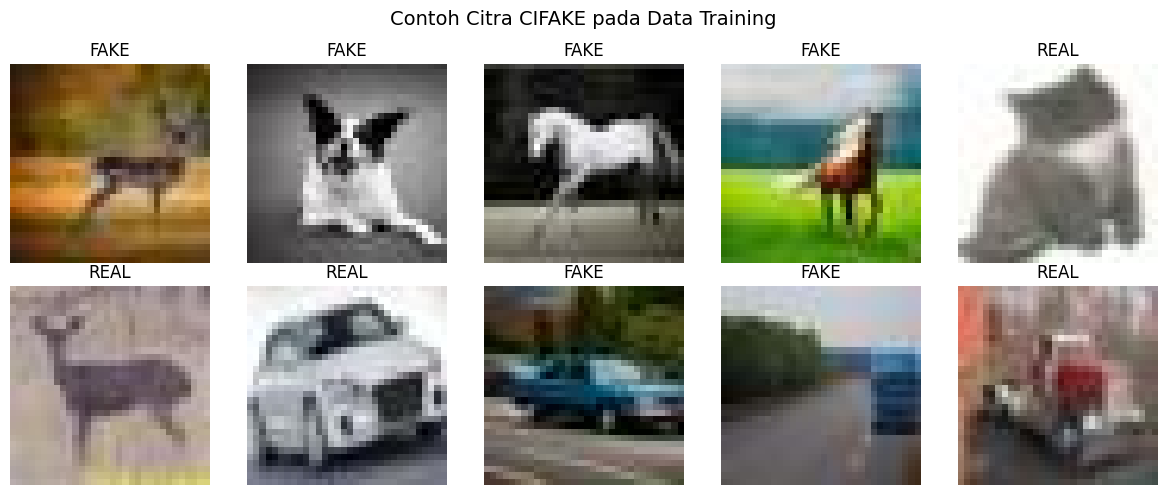

In [11]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].numpy())

    label = CLASS_NAMES[int(labels[i].numpy())]

    plt.title(label)
    plt.axis("off")

plt.suptitle(
    "Contoh Citra CIFAKE pada Data Training",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Model CNN



Model CNN digunakan untuk melakukan klasifikasi biner antara citra REAL dan FAKE.

Arsitektur yang digunakan mengikuti rancangan penelitian:

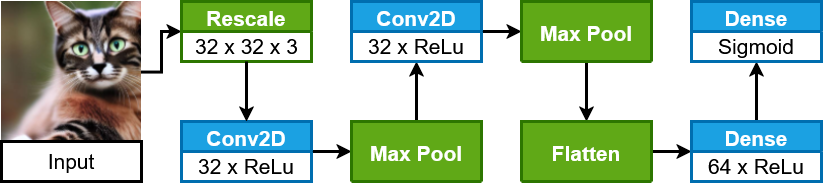

Optimizer:
Adam

Loss function:
Binary Cross Entropy

## Membangun CNN

In [12]:
from prompt_toolkit import filters
def build_model(seed=SEED):
  # Melakukan reset state sebelum membangun model
  tf.keras.utils.set_random_seed(seed)

  model = tf.keras.Sequential(
      [
          tf.keras.layers.Input(
              shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)
          ),

          # Conv Block 1
          tf.keras.layers.Conv2D(
              filters=32,
              kernel_size=(3, 3),
              activation="relu",
              name="conv2d_1"
          ),

          tf.keras.layers.MaxPooling2D(
              pool_size=(2, 2),
              name="maxpool_1"
          ),

          # Conv Block 2
          tf.keras.layers.Conv2D(
              filters=32,
              kernel_size=(3, 3),
              activation="relu",
              name="conv2d_2"
          ),

          tf.keras.layers.MaxPooling2D(
              pool_size=(2, 2),
              name="maxpool_2"
          ),

          # Classification
          tf.keras.layers.Flatten(
              name="flatten"
          ),

          tf.keras.layers.Dense(
              64,
              activation="relu",
              name="dense_64"
          ),

          tf.keras.layers.Dense(
              1,
              activation="sigmoid",
              name="output"
          )
      ],
      name="cnn_cifake"
  )

  return model

model = build_model()

print("Model Berhasil Dibangun")

Model Berhasil Dibangun


## Verifikasi Arsitektur CNN

In [13]:
model.summary()

print("\nJumlah Parameter Total: ")
print(f"{model.count_params():,}")

print("\nVerifikasi Arsitektur Berhasil")

Model: "cnn_cifake"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling2D)        │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 13, 13, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_2 (MaxPooling2D)        │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,001 (328.13 KB)

 Trainable params: 84,001 (328.13 KB)

 Non-trainable params: 0 (0.00 B)


Jumlah Parameter Total: 
84,001

Verifikasi Arsitektur Berhasil


## Utility Evaluasi Model

In [14]:
def predict_dataset(model, dataset):
    # Mengambil label aktual
    y_true = np.concatenate([
        labels.numpy().astype(int).ravel()
        for _, labels in dataset
    ])

    # Mengambil probabilitas prediksi
    y_prob = model.predict(
        dataset,
        verbose=0
    ).ravel()

    # Mengubah probabilitas menjadi label
    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    return y_true, y_prob, y_pred


def evaluate_model(
    model,
    dataset,
    split_name="Test"
):
    # Menghitung loss dan accuracy
    evaluation = model.evaluate(
        dataset,
        verbose=0,
        return_dict=True
    )

    # Mengambil prediksi model
    y_true, y_prob, y_pred = predict_dataset(
        model,
        dataset
    )

    # Menghitung precision
    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Menghitung recall
    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Menghitung F1-score
    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Membuat confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    # Membuat classification report
    report_dict = classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(
        report_dict
    ).T

    return {
        "Split": split_name,
        "Loss": float(evaluation["loss"]),
        "Accuracy": float(evaluation["accuracy"]),
        "Precision": float(precision),
        "Recall": float(recall),
        "F1-Score": float(f1),
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred,
        "confusion_matrix": cm,
        "classification_report": report_df
    }


def get_best_epoch(history):
  val_loss = np.array(history.history["val_loss"])

  val_accuracy = np.array(history.history["val_accuracy"])

  best_lost_epoch = int(np.argmin(val_loss) + 1)

  best_accuracy_epoch = int(np.argmax(val_accuracy) + 1)

  return (
      best_lost_epoch,
      best_accuracy_epoch
  )

# Konfigurasi *Learning Rate Range Test*



Learning Rate Range Test digunakan untuk memperoleh rentang learning rate yang
akan digunakan oleh Cyclical Learning Rate.

Rancangan:

- Start learning rate = 1e-10
- End learning rate = 1e-1
- Durasi = 5 epoch
- Kenaikan learning rate dilakukan secara eksponensial melalui faktor pengali q.
- Loss dicatat pada setiap batch.

Hasil pengujian kemudian digunakan untuk menentukan:
- base_lr
- max_lr

## Menjalankan Learning Rate Range Test

In [15]:
# Menjalankan Learning Rate Range Test
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

train_ds_lrrt = make_dataset(
    train_paths,
    train_labels,
    shuffle=True,
    seed=SEED,
    cache=False
)

steps_per_epoch = math.ceil(len(train_paths) / BATCH_SIZE)

N = LRRT_EPOCHS * steps_per_epoch

if N < 2:
    raise RuntimeError("Jumlah total step LRRT harus lebih dari 1.")

# Menghitung faktor pengali learning rate secara eksponensial
q = (LRRT_END / LRRT_START) ** (1 / (N - 1))

print("LEARNING RATE RANGE TEST\n")
print(f"Start LR          : {LRRT_START:.2e}")
print(f"End LR            : {LRRT_END:.2e}")
print(f"Epoch             : {LRRT_EPOCHS}")
print(f"Steps / epoch     : {steps_per_epoch:,}")
print(f"Total steps (N)   : {N:,}")
print(f"Multiplier (q)    : {q:.8f}")

# Membuat model khusus untuk LRRT
model_lrrt = build_model(seed=SEED)

optimizer_lrrt = tf.keras.optimizers.Adam(learning_rate=LRRT_START)

bce_loss = tf.keras.losses.BinaryCrossentropy()

lr_values = []
raw_loss_values = []
smooth_loss_values = []

beta = 0.98
avg_loss = 0.0
current_lr = LRRT_START
global_step = 0
epoch_loss_summary = []

training_stopped = False

print("\nMemulai Learning Rate Range Test...")

for epoch in range(LRRT_EPOCHS):

    epoch_raw_losses = []

    for batch_images, batch_labels in train_ds_lrrt:

        global_step += 1

        optimizer_lrrt.learning_rate.assign(current_lr)

        batch_labels = tf.reshape(batch_labels,(-1, 1))

        with tf.GradientTape() as tape:

            predictions = model_lrrt(batch_images, training=True)

            loss = bce_loss(batch_labels, predictions)

        gradients = tape.gradient(loss, model_lrrt.trainable_variables)

        optimizer_lrrt.apply_gradients(
            zip(gradients, model_lrrt.trainable_variables)
        )

        loss_value = float(loss.numpy())

        if not np.isfinite(loss_value):

            print(
                f"\nTraining dihentikan pada step "
                f"{global_step} karena loss non-finite."
            )

            training_stopped = True
            break

        avg_loss = (beta * avg_loss + (1 - beta) * loss_value)

        smooth_loss = (avg_loss/ (1 - beta ** global_step))

        lr_values.append(current_lr)

        raw_loss_values.append(loss_value)

        smooth_loss_values.append(smooth_loss)

        epoch_raw_losses.append(loss_value)

        current_lr *= q

    if epoch_raw_losses:
        epoch_mean_loss = float(np.mean(epoch_raw_losses))

        epoch_loss_summary.append(epoch_mean_loss)

        print(
            f"Epoch {epoch + 1}/{LRRT_EPOCHS} "
            f"| mean loss = {epoch_mean_loss:.6f} "
            f"| last lr = {lr_values[-1]:.2e}"
        )

    if training_stopped:
        break

print("\nLearning Rate Range Test selesai.")

lr_values = np.array(lr_values,dtype=np.float64)

raw_loss_values = np.array(raw_loss_values, dtype=np.float64)

smooth_loss_values = np.array(smooth_loss_values, dtype=np.float64)

if len(lr_values) == 0:
    raise RuntimeError("LRRT tidak menghasilkan observasi.")

lrrt_df = pd.DataFrame({
    "learning_rate": lr_values,
    "raw_loss": raw_loss_values,
    "smoothed_loss": smooth_loss_values
})

lrrt_path = (RESULTS_DIR/ "learning_rate_range_test.csv")

lrrt_df.to_csv(lrrt_path,index=False)

print("\nHASIL LRRT\n")
print(f"Jumlah observasi       : {len(lr_values):,}")
print(f"LR aktual yang tersapu : {lr_values.min():.2e} - {lr_values.max():.2e}")
print(f"Raw loss minimum       : {raw_loss_values.min():.6f}")
print(f"Smoothed loss minimum  : {smooth_loss_values.min():.6f}")
print(f"File hasil             : {lrrt_path}")

LEARNING RATE RANGE TEST

Start LR          : 1.00e-10
End LR            : 1.00e-01
Epoch             : 5
Steps / epoch     : 2,813
Total steps (N)   : 14,065
Multiplier (q)    : 1.00147458

Memulai Learning Rate Range Test...
Epoch 1/5 | mean loss = 0.695156 | last lr = 6.30e-09
Epoch 2/5 | mean loss = 0.694838 | last lr = 3.98e-07
Epoch 3/5 | mean loss = 0.671638 | last lr = 2.51e-05
Epoch 4/5 | mean loss = 0.440245 | last lr = 1.58e-03
Epoch 5/5 | mean loss = 0.441884 | last lr = 1.00e-01

Learning Rate Range Test selesai.

HASIL LRRT

Jumlah observasi       : 14,065
LR aktual yang tersapu : 1.00e-10 - 1.00e-01
Raw loss minimum       : 0.075752
Smoothed loss minimum  : 0.315597
File hasil             : /content/results/learning_rate_range_test.csv


## Visualisasi Learning Rate Range Test

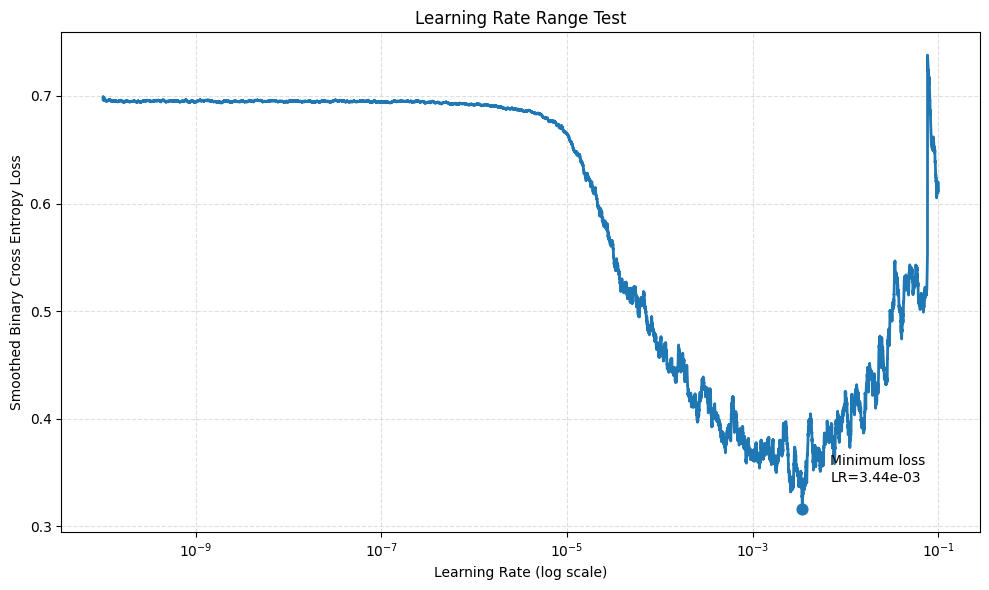


HASIL LRRT
Learning rate minimum loss : 3.44e-03
Minimum smoothed loss      : 0.315597


In [16]:
valid_mask = (
    np.isfinite(lr_values)
    & np.isfinite(smooth_loss_values)
)

plot_lr = lr_values[valid_mask]
plot_loss = smooth_loss_values[valid_mask]

min_idx = np.argmin(plot_loss)

min_lr = plot_lr[min_idx]
min_loss = plot_loss[min_idx]

plt.figure(figsize=(10, 6))

plt.plot(
    plot_lr,
    plot_loss,
    linewidth=2
)

plt.scatter(
    [min_lr],
    [min_loss],
    s=60,
    zorder=5
)

plt.xscale("log")

plt.xlabel("Learning Rate (log scale)")

plt.ylabel("Smoothed Binary Cross Entropy Loss")

plt.title("Learning Rate Range Test")

plt.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.4
)

plt.annotate(
    f"Minimum loss\nLR={min_lr:.2e}",
    xy=(min_lr, min_loss),
    xytext=(20, 20),
    textcoords="offset points"
)

plt.tight_layout()
plt.show()

print("\nHASIL LRRT")
print(f"Learning rate minimum loss : {min_lr:.2e}")
print(f"Minimum smoothed loss      : {min_loss:.6f}")

## Menentukan Base LR dan Max LR

In [18]:
# Menyaring learning rate dan loss yang memiliki nilai valid
valid_mask = (
    np.isfinite(lr_values) &
    np.isfinite(smooth_loss_values)
)

# mengambil learning rate valid untuk analisis
analysis_lr = np.asarray(lr_values, dtype=np.float64)[valid_mask]

# Mengambil loss valid untuk analisis
analysis_loss = np.asarray(smooth_loss_values, dtype=np.float64)[valid_mask]

# Memastikan jumlah data cukup untuk analisis kurva
if len(analysis_loss) < 100:
    raise ValueError("Data LRRT terlalu sedikit untuk menentukan learning rate.")

# Menentukan jumlah kelompok berdasarkan jumlah observasi
bin_count = min(
    300,
    max(80, int(np.sqrt(len(analysis_loss)) * 3))
)

# Membuat batas setiap kelompok data
bin_edges = np.linspace(0, len(analysis_loss), bin_count + 1, dtype=int)

binned_lr = []
binned_loss = []
binned_indices = []

# Mengelompokkan observasi LRRT agar noise batch lebih mudah dibaca
for index in range(bin_count):
    start = bin_edges[index]
    end = bin_edges[index + 1]

    if end <= start:
        continue

    # Mengambil median learning rate dalam kelompok
    binned_lr.append(np.median(analysis_lr[start:end]))

    # Mengambil median loss dalam kelompok
    binned_loss.append(np.median(analysis_loss[start:end]))

    # Menyimpan index tengah kelompok terhadap data asli
    binned_indices.append((start + end - 1) // 2)

# Mengubah learning rate hasil pengelompokan menjadi array
binned_lr = np.asarray(binned_lr, dtype=np.float64)

# Mengubah loss hasil pengelompokan menjadi array
binned_loss = np.asarray(binned_loss, dtype=np.float64)

# Mengubah index hasil pengelompokan menjadi array integer
binned_indices = np.asarray(binned_indices, dtype=int)

# Menentukan ukuran jendela untuk mengurangi noice kurva
smooth_window = 11

# Menghaluskan loss hasil pengelompokan menggunakan median berjalan
smoothed_loss = (
    pd.Series(binned_loss)
    .rolling(
        window=smooth_window,
        center=True,
        min_periods=1
    )
    .median()
    .to_numpy()
)

# Mencari indeks loss paling rendah pada seluruh observasi LRRT
minimum_loss_index = np.argmin(analysis_loss)

# Mengambil learning rate ketika loss aktual mencapai minimum
MINIMUM_LR = float(analysis_lr[minimum_loss_index])

# Mengambil nilai loss minimum yang benar-benar tercatat
MINIMUM_LOSS = float(analysis_loss[minimum_loss_index])

# Mencari nilai binned yang paling dekat dengan minimum loss aktual
minimum_binned_index = np.argmin(
    np.abs(
        np.log10(binned_lr) - np.log10(MINIMUM_LR)
    )
)

# Mengambil bagian kurva sebelum minimum untuk menentukan BASE_LR
base_loss_curve = smoothed_loss[:minimum_binned_index + 1]

# Membuat posisi relatif dari awal sampai minimum loss
base_x = np.linspace(0, 1, len(base_loss_curve))

# Mengambil loss pada awal kurva sisi penurunan
base_loss_start = base_loss_curve[0]

# Mengambil loss pada akhir kurva sisi penurunan
base_loss_end = base_loss_curve[-1]

# Menghitung total penurunan loss
base_denominator = (base_loss_start - base_loss_end)

# Memastikan terdapat penurunan loss sebelum minimum
if base_denominator <= 0:
    raise ValueError("Kurva LRRT tidak menunjukkan penurunan loss yang cukup untuk menentukan BASE_LR.")

# Mengubah penurunan loss menjadi skala relatif
base_y = (base_loss_start - base_loss_curve) / base_denominator

# Menghitung jarak kurva terhadap garis diagonal
base_distance = (base_x - base_y)

# Mengabaikan beberapa titik awal agar BASE_LE tidak dipilih terlalu awal
base_distance[:3] = -np.inf

# Mengabaikan beberapa titik terakhir agar BASE_LR tidak terlalu dekat minimum
if len(base_distance) >= 6:
    base_distance[-3:] = -np.inf

# Mencari titik knee dengan jarak terbesar
base_binned_index = np.argmax(base_distance)

# Mengubah indeks binned menjadi indeks pada data LRRT asli
base_lr_index = binned_indices[base_binned_index]

# Menetapkan BASE_LR dari data LRRT asli
BASE_LR = float(analysis_lr[base_lr_index])

# Memulai pencarian MAX_LR setelah minimum loss
post_min_start = minimum_binned_index

# Memastikan terdapat cukup data setelah minimum untuk mencari pola kenaikan
if post_min_start >= len(smoothed_loss) - 10:
    raise ValueError("Data setelah minimum loss terlalu sedikit untuk menentukan MAX_LR.")

# Menentukan ukuran jendela untuk membaca kenaikan setelah kandidat
trend_window = min(smooth_window, len(smoothed_loss) - post_min_start - 1)

# Menentukan jumlah kenaikan yang harus mendominasi dalam jendela
minimum_positive_ratio = 0.60

# Menyiapkan tempat penyimpanan kandidat MAX_LR
max_candidates = []

# Memeriksa setiap titik setelah minimum loss
for candidate in range(post_min_start, len(smoothed_loss) - trend_window):

  # Mengambil loss kandidat pada kurva yang sudah dihaluskan
  candidate_loss_smoothed = smoothed_loss[candidate]

  # Mengambil loss sebelum kandidat
  previous_loss_smoothed = smoothed_loss[candidate - 1]

  # mengambil loss setelah kandidat
  next_loss_smoothed = smoothed_loss[candidate + 1]

  # Memeriksa apakah kandidat merupakan titik lembah local
  is_local_minimum = (
      candidate_loss_smoothed <= previous_loss_smoothed
      and
      candidate_loss_smoothed <= next_loss_smoothed
  )

  # Melewati kandidat yang bukan titik lembah
  if not is_local_minimum:
    continue

  # Mengubah index binned menjadi indeks data LRRT asli
  candidate_origin_index = binned_indices[candidate]

  # Mengambil loss aktual pada posisi kandidat
  candidate_actual_loss = analysis_loss[candidate_origin_index]

  # Mengambil seluruh loss aktual setelah kandidat
  future_actual_loss = analysis_loss[candidate_origin_index + 1:]

  # Melewati kandidat terakhir yang tidak memiliki data setelahnya
  if len(future_actual_loss) == 0:
    continue

  # Mencari loss terendah yang muncul setelah kandidat
  future_minimum_loss = np.min(future_actual_loss)

  # Memastikan tidak ada los slebih rendah setelah MAX_LR
  no_lower_loss_after_candidate = (future_minimum_loss >=candidate_actual_loss)

  # Menolak kandidat jika masih terdapat loss lebih rendah setelahnya
  if not no_lower_loss_after_candidate:
    continue

  # Mengambil loss dalam jendela setelah kandidat
  trend_loss = smoothed_loss[candidate: candidate + trend_window + 1]

  # Menghitung perubahan loss antar titik
  trend_differences = np.diff(trend_loss)

  # Menghitung proporsi perubahan loss yang meningkat
  positive_ratio = np.mean(trend_differences > 0)

  # Memeriksa apakah kenaikan mendominasi jendela setelah kandidat
  sustained_increase = (
      positive_ratio >= minimum_positive_ratio
      and
      trend_loss[-1] > trend_loss[0]
  )

  # Menolak kandidat jika kenaikan belum cukup konsisten
  if not sustained_increase:
    continue

  # Menyimpan kandidat yang memenuhi kriteria
  max_candidates.append(candidate)

# Memastikan setidaknya satu kandidat MAX_LR ditemukan
if len(max_candidates) == 0:
  raise ValueError("MAX_LR tidak dapat ditentukan dari pola LRRT")

# Mengambil kandidat paling awal yang memenuhi seluruh kriteria
max_binned_index = max_candidates[0]

# Mengubah indeks binned menjadi indeks LRRTI asli
max_lr_index = binned_indices[max_binned_index]

# Menentapkan MAX_LR dari learning rate aktual
MAX_LR = float(analysis_lr[max_lr_index])

# Mencari posisi loss aktual yang paling dekat dengan MAX_LR
MAX_LOSS_INDEX = np.argmin(
    np.abs(analysis_loss - MAX_LR)
)

# Mengambil loss aktual pada MAX_LR
MAX_LOSS = float(analysis_loss[MAX_LOSS_INDEX])

# Mengambil seluruh loss setelah MAX_LR
later_loss = analysis_loss[MAX_LOSS_INDEX + 1:]

# Mengambil loss paling rendah setelah MAX_LR
if len(later_loss) > 0:
  LOWEST_LOSS_AFTER_MAX = float(np.min(later_loss))
else:
  LOWEST_LOSS_AFTER_MAX = np.nan

# Memeriksa apakah MAX_LR benar benar memenuhi definisi penelitian
MAX_LR_VALID = (
    np.isnan(LOWEST_LOSS_AFTER_MAX)
    or
    LOWEST_LOSS_AFTER_MAX >= MAX_LR
)

# Menghitung perbandingan MAX_LR terhadap MINIMUM_LR
if MINIMUM_LR > 0:
  LR_MAX_MIN_RATIO = (MAX_LR / MINIMUM_LR)
else:
  LR_MAX_MIN_RATIO = np.nan

print()
print("HASIL PENENTUAN BASE_LR dan MAX_LR")
print()

print(f"BASE_LR: {BASE_LR:.6e}")
print(f"Loss pada BASE_LR: {analysis_loss[np.argmin(np.abs(analysis_lr - BASE_LR))]:.6e}")
print()

print(f"Learning Rate Minimum: {MINIMUM_LR:.6e}")
print(f"Minimum Loss: {MINIMUM_LOSS:.6e}")
print()

print(f"MAX_LR: {MAX_LR:.6e}")
print(f"Loss pada MAX_LR: {MAX_LOSS:.6e}")
print()


HASIL PENENTUAN BASE_LR dan MAX_LR

BASE_LR: 7.487901e-06
Loss pada BASE_LR: 6.756141e-01

Learning Rate Minimum: 3.439348e-03
Minimum Loss: 3.155967e-01

MAX_LR: 1.134543e-02
Loss pada MAX_LR: 3.155967e-01



## Visualisasi Penentuan Base LR dan Max LR

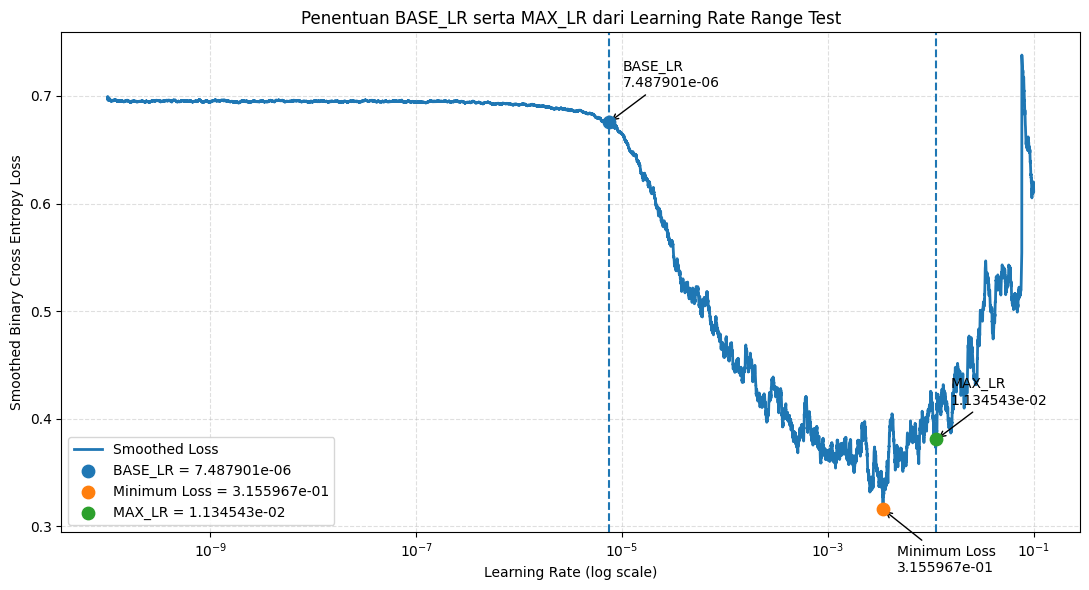

In [19]:
# Menampilkan kurva LRRT beserta titik penentuan learning rate
plt.figure(figsize=(11, 6))

plt.plot(
    analysis_lr,
    analysis_loss,
    linewidth=2,
    label="Smoothed Loss"
)

plt.scatter(
    analysis_lr[base_lr_index],
    analysis_loss[base_lr_index],
    s=80,
    zorder=5,
    label=f"BASE_LR = {BASE_LR:.6e}"
)

plt.scatter(
    analysis_lr[minimum_loss_index],
    analysis_loss[minimum_loss_index],
    s=80,
    zorder=5,
    label=f"Minimum Loss = {analysis_loss[minimum_loss_index]:.6e}"
)

plt.scatter(
    analysis_lr[max_lr_index],
    analysis_loss[max_lr_index],
    s=80,
    zorder=5,
    label=f"MAX_LR = {MAX_LR:.6e}"
)

plt.axvline(
    BASE_LR,
    linestyle="--",
    linewidth=1.5
)

plt.axvline(
    MAX_LR,
    linestyle="--",
    linewidth=1.5
)

plt.annotate(
    f"BASE_LR\n{BASE_LR:.6e}",
    xy=(
        BASE_LR,
        analysis_loss[base_lr_index]
    ),
    xytext=(10, 25),
    textcoords="offset points",
    arrowprops=dict(
        arrowstyle="->"
    )
)

plt.annotate(
    f"Minimum Loss\n{analysis_loss[minimum_loss_index]:.6e}",
    xy=(
        analysis_lr[minimum_loss_index],
        analysis_loss[minimum_loss_index]
    ),
    xytext=(10, -45),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

plt.annotate(
    f"MAX_LR\n{MAX_LR:.6e}",
    xy=(
        MAX_LR,
        analysis_loss[max_lr_index]
    ),
    xytext=(10, 25),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

plt.xscale("log")

plt.xlabel("Learning Rate (log scale)")
plt.ylabel("Smoothed Binary Cross Entropy Loss")
plt.title("Penentuan BASE_LR serta MAX_LR dari Learning Rate Range Test")

plt.legend()

plt.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

# Eksperimen 1 - *Fixed Learning Rate*

Model CNN dilatih menggunakan *learning rate* tetap selama proses pelatihan

Konfigurasi:
- Optimizer: Adam
- Loss: *Binary Cross Entropy*
- Learning Rate: 0.001 atau 1e-3
- Epoch Maksimum: 50
- Dataset: CIFAKE
- Arsitektur: CNN yang telah ditetapkan

Model terbaik dipilih berdasarkan nilai validation loss terendah.


In [20]:
# Membuat model dan checkpoint untuk skenario Fixed Leaerning Rate
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

model_fixed = build_model(seed=SEED)

model_fixed.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=FIXED_LR),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy"]
)

fixed_checkpoint_path = (CHECKPOINT_DIR / "fixed_best.weights.h5")

checkpoint_fixed = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(fixed_checkpoint_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

history_fixed = model_fixed.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint_fixed],
    verbose=1
)

model_fixed.load_weights(fixed_checkpoint_path)

best_epoch_fixed = (np.argmin(history_fixed.history["val_loss"]) + 1)

best_val_loss_fixed = (
    history_fixed.history["val_loss"][best_epoch_fixed - 1]
)

best_val_accuracy_fixed = (history_fixed.history["val_accuracy"][best_epoch_fixed - 1])

print("\nHASIL PELATIHAN FIXED LEARNING RATE\n")
print(f"Learning rate       : {FIXED_LR:.2e}")
print(f"Epoch pelatihan     : {EPOCHS}")
print(f"Epoch terbaik       : {best_epoch_fixed}")
print(f"Best validation loss: {best_val_loss_fixed:.6f}")
print(f"Validation accuracy : {best_val_accuracy_fixed:.6f}")

Epoch 1/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 26s 9ms/step - accuracy: 0.8457 - loss: 0.3475 - val_accuracy: 0.8882 - val_loss: 0.2680
Epoch 2/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 23s 8ms/step - accuracy: 0.9054 - loss: 0.2328 - val_accuracy: 0.9131 - val_loss: 0.2083
Epoch 3/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 23s 8ms/step - accuracy: 0.9210 - loss: 0.1974 - val_accuracy: 0.9212 - val_loss: 0.1905
Epoch 4/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 26s 9ms/step - accuracy: 0.9303 - loss: 0.1763 - val_accuracy: 0.9323 - val_loss: 0.1710
Epoch 5/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - accuracy: 0.9350 - loss: 0.1627 - val_accuracy: 0.9252 - val_loss: 0.1863
Epoch 6/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - accuracy: 0.9406 - loss: 0.1523 - val_accuracy: 0.9278 - val_loss: 0.1820
Epoch 7/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 23s 8ms/step - accuracy: 0.9450 - loss: 0.1389 - val_accuracy: 0.9334 - val_loss: 0.1648
Epoch 8/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.9503 - loss: 0

## Visualisasi Loss *Fixed Learning Rate*

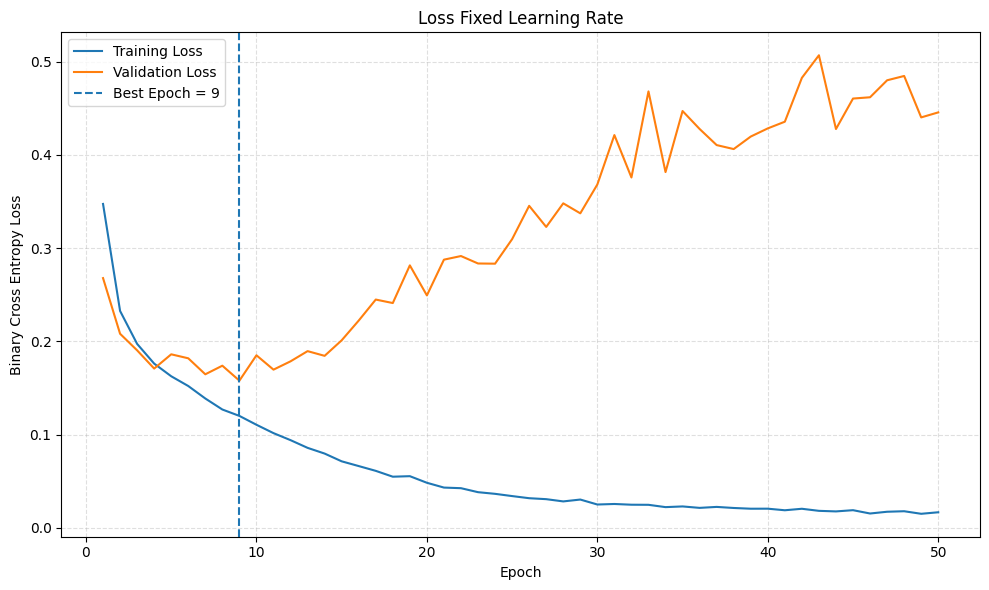

In [21]:
# Menampilkan kurva loss pelatihan Fixed Learning Rate
epochs_range = range(
    1,
    len(history_fixed.history["loss"]) + 1
)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    history_fixed.history["loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history_fixed.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch_fixed,
    linestyle="--",
    label=f"Best Epoch = {best_epoch_fixed}"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross Entropy Loss")
plt.title("Loss Fixed Learning Rate")
plt.legend()
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

## Visualisasi Accuracy Fixed Learning Rate

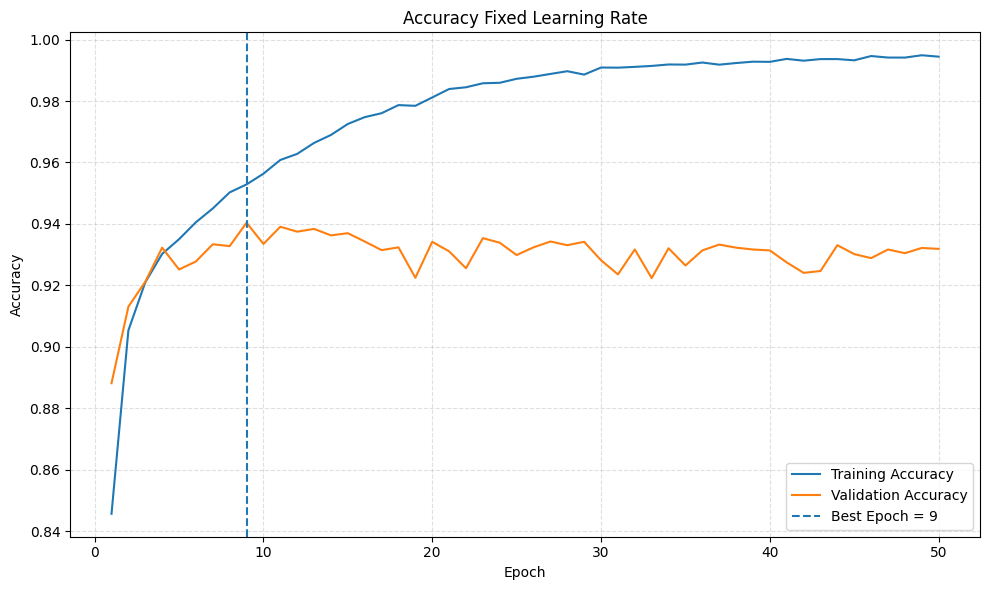

In [22]:
# Menampilkan kurva accuracy pelatihan Fixed Learning Rate
plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    history_fixed.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history_fixed.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    best_epoch_fixed,
    linestyle="--",
    label=f"Best Epoch = {best_epoch_fixed}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Fixed Learning Rate")
plt.legend()
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

## Evaluasi Fixed Learning Rate pada Data Testing

In [23]:
# Mengevaluasi model terbaik pada data pengujian
test_results_fixed = model_fixed.evaluate(
    test_ds,
    verbose=0,
    return_dict=True
)

y_true_fixed = []
y_probability_fixed = []

for batch_images, batch_labels in test_ds:

    batch_probability = model_fixed.predict(
        batch_images,
        verbose=0
    ).reshape(-1)

    y_true_fixed.extend(
        batch_labels.numpy().astype(int)
    )

    y_probability_fixed.extend(
        batch_probability
    )

y_true_fixed = np.array(
    y_true_fixed
)

y_probability_fixed = np.array(
    y_probability_fixed
)

y_pred_fixed = (
    y_probability_fixed >= 0.5
).astype(int)

fixed_accuracy = accuracy_score(
    y_true_fixed,
    y_pred_fixed
)

fixed_precision = precision_score(
    y_true_fixed,
    y_pred_fixed,
    zero_division=0
)

fixed_recall = recall_score(
    y_true_fixed,
    y_pred_fixed,
    zero_division=0
)

fixed_f1 = f1_score(
    y_true_fixed,
    y_pred_fixed,
    zero_division=0
)

fixed_test_loss = test_results_fixed["loss"]

print("HASIL EVALUASI FIXED LEARNING RATE\n")

print(f"Test Loss     : {fixed_test_loss:.6f}")
print(f"Test Accuracy : {fixed_accuracy:.6f}")
print(f"Test Precision: {fixed_precision:.6f}")
print(f"Test Recall   : {fixed_recall:.6f}")
print(f"Test F1-Score : {fixed_f1:.6f}")

HASIL EVALUASI FIXED LEARNING RATE

Test Loss     : 0.164628
Test Accuracy : 0.938850
Test Precision: 0.938894
Test Recall   : 0.938800
Test F1-Score : 0.938847


## Classification Report dan Confusion Matrix Fixed Learning Rate

CLASSIFICATION REPORT

              precision    recall  f1-score   support

        REAL     0.9388    0.9389    0.9389     10000
        FAKE     0.9389    0.9388    0.9388     10000

    accuracy                         0.9388     20000
   macro avg     0.9389    0.9388    0.9388     20000
weighted avg     0.9389    0.9388    0.9388     20000

CONFUSION MATRIX

[[9389  611]
 [ 612 9388]]


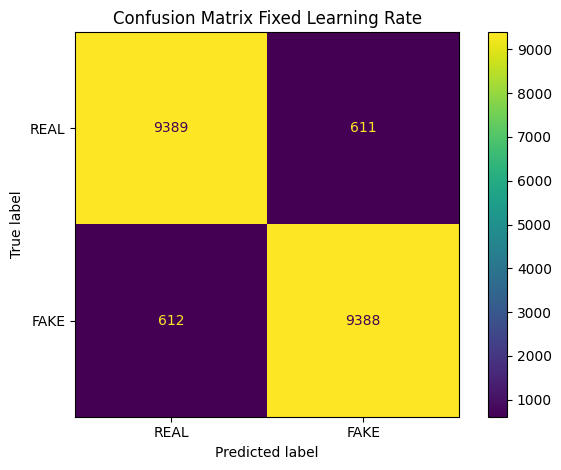

In [24]:
# Menampilkan classification report dan confusion matrix
print("CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_true_fixed,
        y_pred_fixed,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

confusion_fixed = confusion_matrix(
    y_true_fixed,
    y_pred_fixed
)

print("CONFUSION MATRIX\n")
print(confusion_fixed)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_fixed,
    display_labels=CLASS_NAMES
).plot()

plt.title(
    "Confusion Matrix Fixed Learning Rate"
)

plt.tight_layout()
plt.show()

## Menyimpan hasil Fixed Learning Rate

In [25]:
# Mengambil seluruh riwayat pelatihan Fixed Learning Rate
fixed_history = pd.DataFrame(
    history_fixed.history
)

# Menambahkan nomor epoch
fixed_history.insert(
    0,
    "Epoch",
    np.arange(
        1,
        len(fixed_history) + 1
    )
)

# Menambahkan nama strategi
fixed_history.insert(
    0,
    "Strategy",
    "Fixed Learning Rate"
)

# Menandai epoch dengan validation loss terbaik
fixed_history["Best Epoch"] = (
    fixed_history["val_loss"]
    == fixed_history["val_loss"].min()
)

# Menampilkan seluruh riwayat pelatihan
display(
    fixed_history
)

# Menyimpan seluruh riwayat setiap epoch
fixed_history.to_csv(
    RESULTS_DIR / "fixed_training_history.csv",
    index=False
)

# Menyimpan hasil evaluasi akhir pada data testing
fixed_results = pd.DataFrame([
    {
        "Strategy": "Fixed Learning Rate",
        "Best Epoch": best_epoch_fixed,
        "Test Loss": fixed_test_loss,
        "Test Accuracy": fixed_accuracy,
        "Test Precision": fixed_precision,
        "Test Recall": fixed_recall,
        "Test F1-Score": fixed_f1
    }
])

# Menampilkan hasil evaluasi akhir
display(
    fixed_results
)

# Menyimpan hasil evaluasi akhir
fixed_results.to_csv(
    RESULTS_DIR / "fixed_test_results.csv",
    index=False
)

,Strategy,Epoch,accuracy,loss,val_accuracy,val_loss,Best Epoch
0,Fixed Learning Rate,1,0.845733,0.347519,0.8882,0.267985,False
1,Fixed Learning Rate,2,0.905400,0.232757,0.9131,0.208277,False
2,Fixed Learning Rate,3,0.921022,0.197425,0.9212,0.190507,False
3,Fixed Learning Rate,4,0.930267,0.176280,0.9323,0.170974,False
4,Fixed Learning Rate,5,0.935044,0.162710,0.9252,0.186257,False
5,Fixed Learning Rate,6,0.940567,0.152252,0.9278,0.181971,False
6,Fixed Learning Rate,7,0.945044,0.138869,0.9334,0.164827,False
7,Fixed Learning Rate,8,0.950278,0.127058,0.9328,0.174043,False
8,Fixed Learning Rate,9,0.952867,0.120195,0.9404,0.158009,True
9,Fixed Learning Rate,10,0.956356,0.110706,0.9335,0.185203,False


,Strategy,Best Epoch,Test Loss,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,Fixed Learning Rate,9,0.164628,0.93885,0.938894,0.9388,0.938847


# Eksperimen 2 - *Cyclical Learning Rate (CLR) Triangular2*

Model CNN dilatih menggunakan **Cyclical Learning Rate mode Triangular2**

Learning rate bergerak secara suklik antara `BASE_LR` dan `MAX_LR`, sedangkan amplitudo siklus berikutnya dikurangi menjadi setengah dari siklus sebelumnya.

Eksperimen menggunakan arsitektur CNN, optimizer, fungsi loss, dataset, batch size, dan jumlah epoch yang sama dengan skenario **Fixed Learning Rate**.
Perbedaan utama terletak pada strategi learning rate

## Implementasi Schedule Triangular2

In [44]:
# Membuat schedule learning rate Triangular2
class Triangular2LearningRate(tf.keras.optimizers.schedules.LearningRateSchedule):

    # Menginisiasi parameter schedule
    def __init__(self, base_lr, max_lr, step_size):
        super().__init__()

        # Memastikan base learning rate valid
        if base_lr <= 0:
            raise ValueError("base_lr harus lebih besar dari 0.")

        # Memastikan max learning rate lebih besar dari base learning rate
        if max_lr <= base_lr:
            raise ValueError("max_lr harus lebih besar dari base_lr.")

        # Memastikan step size valid
        if step_size <= 0:
            raise ValueError("step_size harus lebih besar dari 0.")

        # Menyimpan base learning rate
        self.base_lr = float(base_lr)

        # Menyimpan max learning rate
        self.max_lr = float(max_lr)

        # Menyimpan panjang setengah siklus
        self.step_size = float(step_size)

    # Menghitung learning rate berdasarkan training step
    def __call__(self, step):

        # Mengubah step menjadi float32
        step = tf.cast(step, tf.float32)

        # Menentukan nomor siklus
        cycle = tf.floor(1.0 + step / (2.0 * self.step_size))

        # Menentukan posisi step dalam siklus
        x = tf.abs(step / self.step_size - 2.0 * cycle + 1.0)

        # Membentuk pola segitiga
        scale = tf.maximum(0.0, 1.0 - x)

        # Menghitung selisih learning rate
        amplitude = self.max_lr - self.base_lr

        # Mengurangi amplitudo setiap siklus menjadi setengah
        learning_rate = (
            self.base_lr
            + amplitude
            * scale
            / tf.pow(2.0, cycle - 1.0)
        )

        return learning_rate

    # Menyediakan konfigurasi schedule
    def get_config(self):
        return {
            "base_lr": self.base_lr,
            "max_lr": self.max_lr,
            "step_size": self.step_size
        }


# Memeriksa method call
print(
    "Class Triangular2LearningRate berhasil Dibuat"
)

Class Triangular2LearningRate berhasil Dibuat


## Konfigurasi CLR

In [46]:
# Memastikan BASE_LR dan MAX_LR sudah tersedia
if BASE_LR is None or MAX_LR is None:
  raise ValueError("BASE_LR dan MAX_LR belum ditentukan")

# Memastukan MAX_LR lebih besar dari BASE_LR
if MAX_LR <= BASE_LR:
  raise ValueError("MAX_LR harus lebih besar dari BASE_LR")

# Menghitung step size berdasarkan jumlah batch per epoch
STEP_SIZE = (STEP_SIZE_MULTIPLIER * STEPS_PER_EPOCH)

# menghitung jumlah seluruh training step
TOTAL_TRAINING_STEPS = (EPOCHS * STEPS_PER_EPOCH)

# Membuat schedule learning rate CLR
clr_schedule = Triangular2LearningRate(
    base_lr=BASE_LR,
    max_lr=MAX_LR,
    step_size=STEP_SIZE
)

# Menampilkan konfigurasi eksperimen
print()
print("KONFIGURASI CLR")
print()

print(f"BASE LR: {BASE_LR:.2e}")
print(f"MAX LR: {MAX_LR:.2e}")

print(f"Step per epoch: {STEPS_PER_EPOCH}")
print(f"Step Sie: {STEP_SIZE:,}")

print(f"Total training steps: {TOTAL_TRAINING_STEPS:,}")
print(f"Epoch: {EPOCHS}")

print(f"Full Cycle: {2 * STEPS_PER_EPOCH} steps")


KONFIGURASI CLR

BASE LR: 7.49e-06
MAX LR: 1.13e-02
Step per epoch: 2813
Step Sie: 11,252
Total training steps: 140,650
Epoch: 50
Full Cycle: 5626 steps


## Verifikasi Schedule Triangular2
Visualisasi ini digunakan untuk memastikan bahwa schedule menghasilkan pola learning rate sesuai karakteristik Triangular2 sebelum digunakan dalam proses pelatihan model.

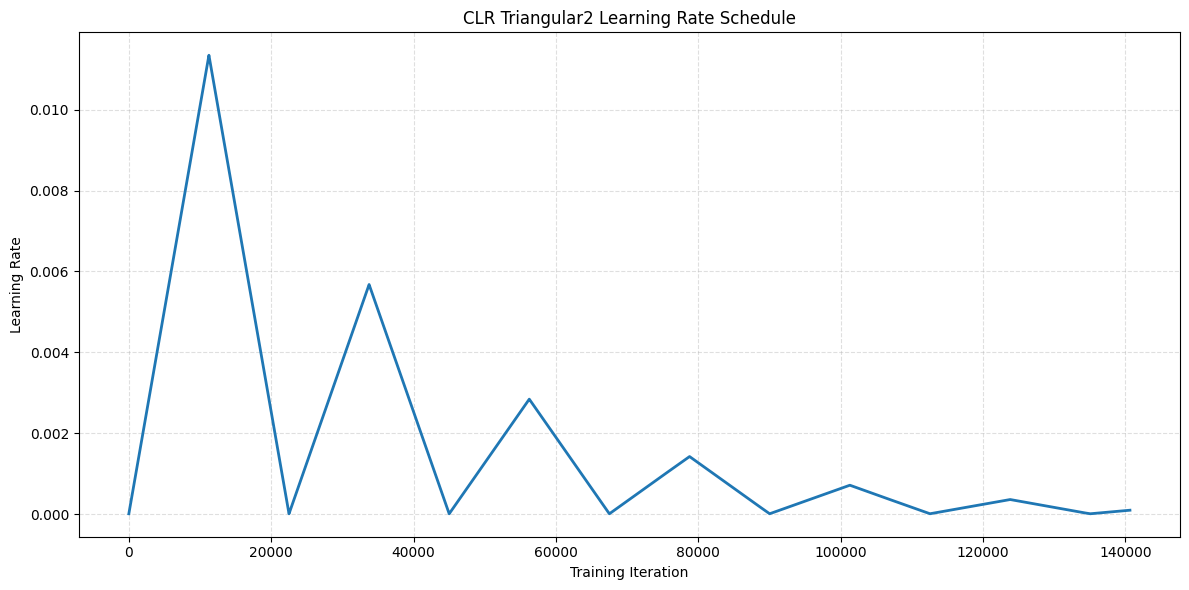


Verifikasi Schedule Triangular2

LR Minimum hasil schedule: 7.49e-06
LR Maximum hasil schedule: 1.13e-02
Base LR: 7.49e-06
Max LR: 1.13e-02


In [47]:
# Membuat step untuk memeriksa schedule
steps_for_check = np.arange(TOTAL_TRAINING_STEPS + 1, dtype=np.int64)

# Menghitung learning rate pada setiap step
lr_check = clr_schedule(tf.constant(steps_for_check, dtype=tf.float32)).numpy()

# Menampilkan grafik schedule
plt.figure(figsize=(12, 6))

plt.plot(steps_for_check, lr_check, linewidth=2)

plt.xlabel("Training Iteration")
plt.ylabel("Learning Rate")
plt.title("CLR Triangular2 Learning Rate Schedule")

plt.grid(
    True,
    linestyle="--",
    which="both",
    alpha=0.4
)

plt.tight_layout()
plt.show()

print()

print("Verifikasi Schedule Triangular2")
print()

print(f"LR Minimum hasil schedule: {lr_check.min():.2e}")
print(f"LR Maximum hasil schedule: {lr_check.max():.2e}")

print(f"Base LR: {BASE_LR:.2e}")
print(f"Max LR: {MAX_LR:.2e}")

## Pencatatan Learning Rate selama Pelatihan

In [48]:
class LearningRateHistory(tf.keras.callbacks.Callback):

  # Membuat konstruktor callback dengan menerima schedule CLR
  def __init__(self, schedule):
    super().__init__()

    # Menyimpan schedule yang digunakan dalam training
    self.schedule = schedule

    # Menyiapkan list untuk menyimpan training step
    self.steps = []

    # Menyiapkan list untuk menyimpan learning step
    self.learning_rates = []

  # Mengatur ulang pencatatan saat training dimulai
  def on_train_begin(self, logs=None):
    self.steps = []
    self.learning_rates = []

  # Mencatat learning rate sebelum setiap batch training dijalankan
  def on_train_batch_begin(self, batch, logs=None):

    # Mengambil training step saat ini dari optimizer
    step = int(self.model.optimizer.iterations.numpy())

    # Menghitung learning rate schedule pada training step tersebut
    learning_rate = float(
        self.schedule(
        tf.constant(step, dtype=tf.float32)
      ).numpy()
    )

    # Menyimpan training step yang sedang digunakan
    self.steps.append(step)

    # Menyimpan learning rate pada training step tersebut
    self.learning_rates.append(learning_rate)

print("Callback Learning Rate History berhasil dibuat")

Callback Learning Rate History berhasil dibuat


## Persiapan Model dan dataset CLR

In [50]:
# Membersihkan session tensorflow dari model atau graph sebelumnya
tf.keras.backend.clear_session()

# Membersihkan objek python yang sudah tidak digunakan dari memory
gc.collect()

# Menetapkan seed untuk reproduktifitas
tf.keras.utils.set_random_seed(SEED)

# Memastikan folder checkpoint tersedia
CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Menentukan lokasi file checkpoint model CLR terbaik
clr_checkpoint_path = (CHECKPOINT_DIR / "clr_best.weights.h5")

# Pemeriksaan checkpoint lama
if clr_checkpoint_path.exists():
    clr_checkpoint_path.unlink()

# Membuat model CNN baru menggunakan arsitektur yang sama
model_clr = build_model(seed=SEED)

model_clr.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=clr_schedule
    ),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy"]
)

# Membuat dataset training khusus eksperimen CLR
train_ds_clr = make_dataset(
    train_paths,
    train_labels,
    shuffle=True,
    seed=SEED,
    cache=False
)

# Membuat callback untuk mencatat learning rate pada setiap training step
lr_history_callback = LearningRateHistory(
    clr_schedule
)

# Membuat callback untuk menyimpan model dengan validation loss terbaik
checkpoint_clr = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(clr_checkpoint_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

print("Persiapan Model dan Dataset CLR Selesai")

Persiapan Model dan Dataset CLR Selesai


## Pelatihan Model dengan CLR Triangular2

In [51]:
print("Training CLR Triangular2\n")

print(f"Base LR: {BASE_LR:.2e}")
print(f"Max LR: {MAX_LR:.2e}")

print(f"Step Size: {STEP_SIZE:,}")
print(f"Epoch: {EPOCHS}")

print()

# Menjalankan training model menggunakan dataset training dan validation
history_clr = model_clr.fit(
    train_ds_clr,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        lr_history_callback,
        checkpoint_clr
    ],
    verbose=2
)

# Memuat kembali bobot model dengan validation loss terbaik
model_clr.load_weights(clr_checkpoint_path)

print("\nModel terbaik CLR berhasil dimuat")

Training CLR Triangular2

Base LR: 7.49e-06
Max LR: 1.13e-02
Step Size: 11,252
Epoch: 50

Epoch 1/50
2813/2813 - 31s - 11ms/step - accuracy: 0.8168 - loss: 0.3913 - val_accuracy: 0.8663 - val_loss: 0.3085
Epoch 2/50
2813/2813 - 29s - 10ms/step - accuracy: 0.8861 - loss: 0.2749 - val_accuracy: 0.8990 - val_loss: 0.2479
Epoch 3/50
2813/2813 - 30s - 11ms/step - accuracy: 0.8921 - loss: 0.2641 - val_accuracy: 0.8962 - val_loss: 0.2429
Epoch 4/50
2813/2813 - 38s - 14ms/step - accuracy: 0.8934 - loss: 0.2610 - val_accuracy: 0.8956 - val_loss: 0.2466
Epoch 5/50
2813/2813 - 33s - 12ms/step - accuracy: 0.9013 - loss: 0.2483 - val_accuracy: 0.9101 - val_loss: 0.2314
Epoch 6/50
2813/2813 - 46s - 16ms/step - accuracy: 0.9144 - loss: 0.2147 - val_accuracy: 0.9111 - val_loss: 0.2529
Epoch 7/50
2813/2813 - 85s - 30ms/step - accuracy: 0.9281 - loss: 0.1798 - val_accuracy: 0.9268 - val_loss: 0.1926
Epoch 8/50
2813/2813 - 63s - 22ms/step - accuracy: 0.9424 - loss: 0.1436 - val_accuracy: 0.9304 - val_los

## Verifikasi Learning Rate Aktual dan Riwayat Pelatihan

Data learning rate yang dicatat selama training diolah menjadi data per-step dan ringkasan per-epoch. Data tersebut kemudian digabungkan dengan riwayat loss dan accuracy hasil pelatihan.

In [53]:
# Mengubah daftar training step menjadi numpy array.
lr_steps = np.asarray(
    lr_history_callback.steps,
    dtype=np.int64
)

# Mengubah daftar learning rate menjadi numpy array.
lr_values = np.asarray(
    lr_history_callback.learning_rates,
    dtype=np.float64
)

# Mengubah training step menjadi nomor epoch.
lr_epochs = (
    lr_steps // STEPS_PER_EPOCH
) + 1

# Membuat dataframe berisi learning rate pada setiap training step.
clr_lr_history = pd.DataFrame({
    "Epoch": lr_epochs,
    "Training Step": lr_steps,
    "Learning Rate": lr_values
})

# Mengelompokkan learning rate berdasarkan epoch.
epoch_lr_summary = (
    clr_lr_history
    .groupby("Epoch")["Learning Rate"]
    .agg(
        Learning_Rate_Min="min",
        Learning_Rate_Max="max",
        Learning_Rate_Mean="mean"
    )
    .reset_index()
)

# Mengubah history TensorFlow menjadi dataframe.
clr_history_df = pd.DataFrame(
    history_clr.history
)

# Menambahkan nomor epoch sebagai kolom pertama.
clr_history_df.insert(
    0,
    "Epoch",
    np.arange(
        1,
        len(clr_history_df) + 1
    )
)

# Menggabungkan history training dengan ringkasan learning rate per epoch.
clr_history_df = clr_history_df.merge(
    epoch_lr_summary,
    on="Epoch",
    how="left"
)

# Menentukan epoch dengan validation loss terendah.
clr_best_epoch = (
    np.argmin(
        clr_history_df["val_loss"].to_numpy()
    ) + 1
)

# Menandai baris yang merupakan epoch terbaik.
clr_history_df["Best Epoch"] = (
    clr_history_df["Epoch"]
    == clr_best_epoch
)

# Menampilkan riwayat lengkap training CLR.
display(clr_history_df)

# Menampilkan jumlah training step yang berhasil dicatat.
print(
    f"\nJumlah training step yang tercatat : "
    f"{len(clr_lr_history):,}"
)

# Menampilkan learning rate minimum yang tercatat.
print(
    f"Learning rate minimum aktual        : "
    f"{lr_values.min():.6e}"
)

# Menampilkan learning rate maksimum yang tercatat.
print(
    f"Learning rate maksimum aktual       : "
    f"{lr_values.max():.6e}"
)

,Epoch,accuracy,loss,val_accuracy,val_loss,Learning_Rate_Min,Learning_Rate_Max,Learning_Rate_Mean,Best Epoch
0,1,0.816822,0.391295,0.8663,0.308531,0.000007,0.002841,0.001424,False
1,2,0.886067,0.274940,0.8990,0.247881,0.002842,0.005675,0.004259,False
2,3,0.892122,0.264131,0.8962,0.242880,0.005676,0.008510,0.007093,False
3,4,0.893356,0.261044,0.8956,0.246647,0.008511,0.011344,0.009928,False
4,5,0.901322,0.248293,0.9101,0.231431,0.008512,0.011345,0.009929,False
5,6,0.914389,0.214677,0.9111,0.252892,0.005677,0.008511,0.007094,False
6,7,0.928133,0.179773,0.9268,0.192555,0.002843,0.005676,0.004260,False
7,8,0.942367,0.143584,0.9304,0.186237,0.000008,0.002842,0.001425,True
8,9,0.947811,0.129967,0.9266,0.198376,0.000007,0.001424,0.000716,False
9,10,0.943889,0.139030,0.9253,0.200139,0.001425,0.002841,0.002133,False



Jumlah training step yang tercatat : 140,650
Learning rate minimum aktual        : 7.487900e-06
Learning rate maksimum aktual       : 1.134543e-02


## Visualisasi Learning Rate Aktual Selama Pelatihan

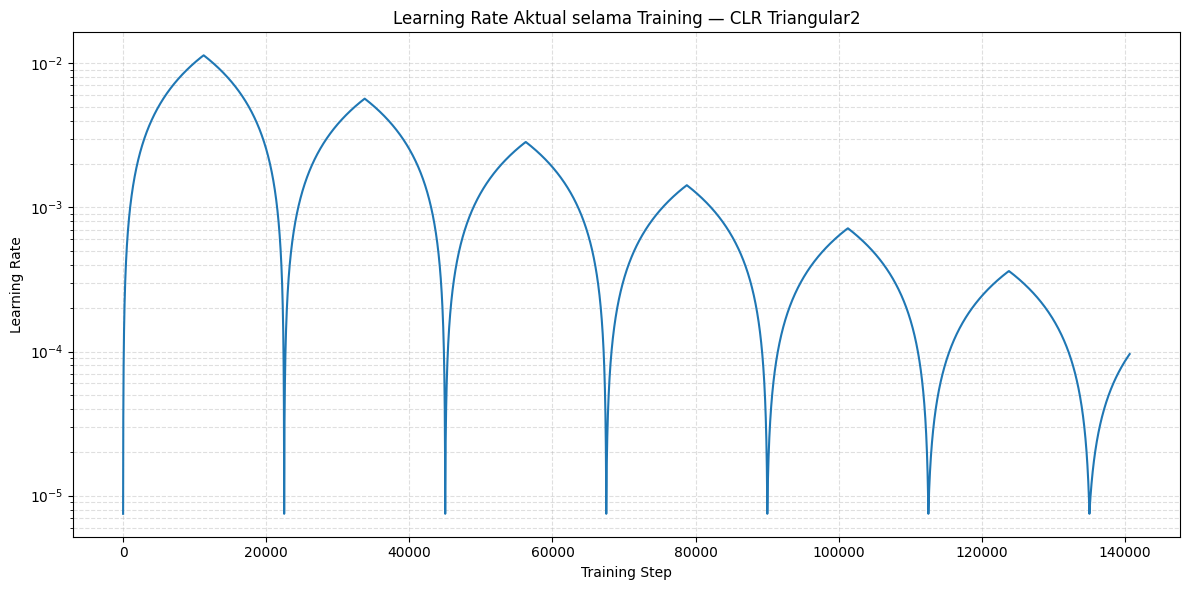

In [55]:
# Membuat area gambar untuk learning rate aktual.
plt.figure(figsize=(12, 6))

# Menggambar learning rate aktual terhadap training step.
plt.plot(
    clr_lr_history["Training Step"],
    clr_lr_history["Learning Rate"],
    linewidth=1.5
)

# Memberikan label pada sumbu horizontal.
plt.xlabel("Training Step")

# Memberikan label pada sumbu vertikal.
plt.ylabel("Learning Rate")

# Memberikan judul grafik learning rate aktual.
plt.title(
    "Learning Rate Aktual selama Training — CLR Triangular2"
)

# Menggunakan skala logaritmik pada sumbu learning rate.
plt.yscale("log")

# Menampilkan grid utama dan grid minor.
plt.grid(
    True,
    linestyle="--",
    which="both",
    alpha=0.4
)

# Menyesuaikan tata letak elemen grafik.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

## Visualisasi Loss dan Learning Rate Aktual

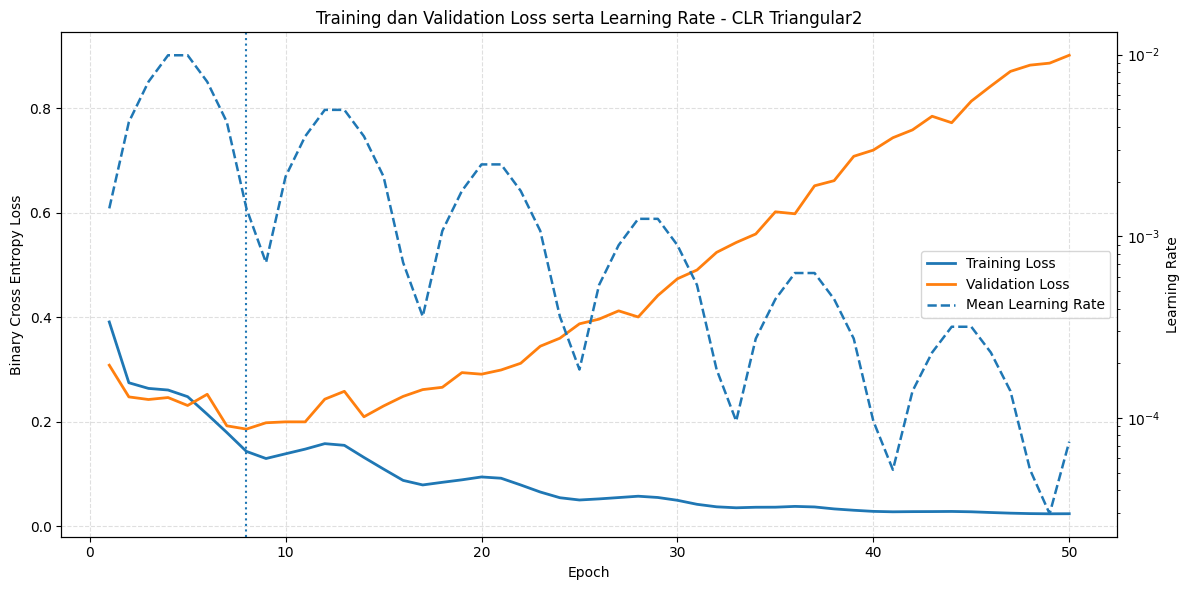

In [56]:
# Mengambil nomor epoch dari DataFrame riwayat training.
epochs_axis_clr = clr_history_df["Epoch"]

# Membuat area grafik utama dengan dua sumbu vertikal.
fig, ax1 = plt.subplots(
    figsize=(12, 6)
)

# Menggambar training loss pada sumbu pertama.
ax1.plot(
    epochs_axis_clr,
    clr_history_df["loss"],
    label="Training Loss",
    linewidth=2
)

# Menggambar validation loss pada sumbu pertama.
ax1.plot(
    epochs_axis_clr,
    clr_history_df["val_loss"],
    label="Validation Loss",
    linewidth=2
)

# Memberikan label epoch pada sumbu horizontal.
ax1.set_xlabel("Epoch")

# Memberikan label loss pada sumbu vertikal pertama.
ax1.set_ylabel(
    "Binary Cross Entropy Loss"
)

# Memberikan judul utama grafik.
ax1.set_title(
    "Training dan Validation Loss serta Learning Rate - CLR Triangular2"
)

# Menandai posisi epoch terbaik berdasarkan validation loss.
ax1.axvline(
    clr_best_epoch,
    linestyle=":",
    linewidth=1.5
)

# Membuat sumbu vertikal kedua untuk learning rate.
ax2 = ax1.twinx()

# Menggambar rata-rata learning rate pada setiap epoch.
ax2.plot(
    epochs_axis_clr,
    clr_history_df["Learning_Rate_Mean"],
    linestyle="--",
    linewidth=1.8,
    label="Mean Learning Rate"
)

# Memberikan label learning rate pada sumbu kedua.
ax2.set_ylabel("Learning Rate")

# Menggunakan skala logaritmik untuk learning rate.
ax2.set_yscale("log")

# Mengambil informasi legend dari grafik loss.
lines_1, labels_1 = ax1.get_legend_handles_labels()

# Mengambil informasi legend dari grafik learning rate.
lines_2, labels_2 = ax2.get_legend_handles_labels()

# Menggabungkan seluruh legend pada satu tempat.
ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="best"
)

# Menampilkan grid pada grafik utama.
ax1.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Menyesuaikan tata letak kedua sumbu.
fig.tight_layout()

# Menampilkan grafik loss dan learning rate.
plt.show()

## Visualisasi Accuracy dan Learning Rate Aktual

Visualisasi ini digunakan untuk mengamati hubungan antara perubahan learning rate dengan training accuracy dan validation accuracy selama proses pelatihan model.

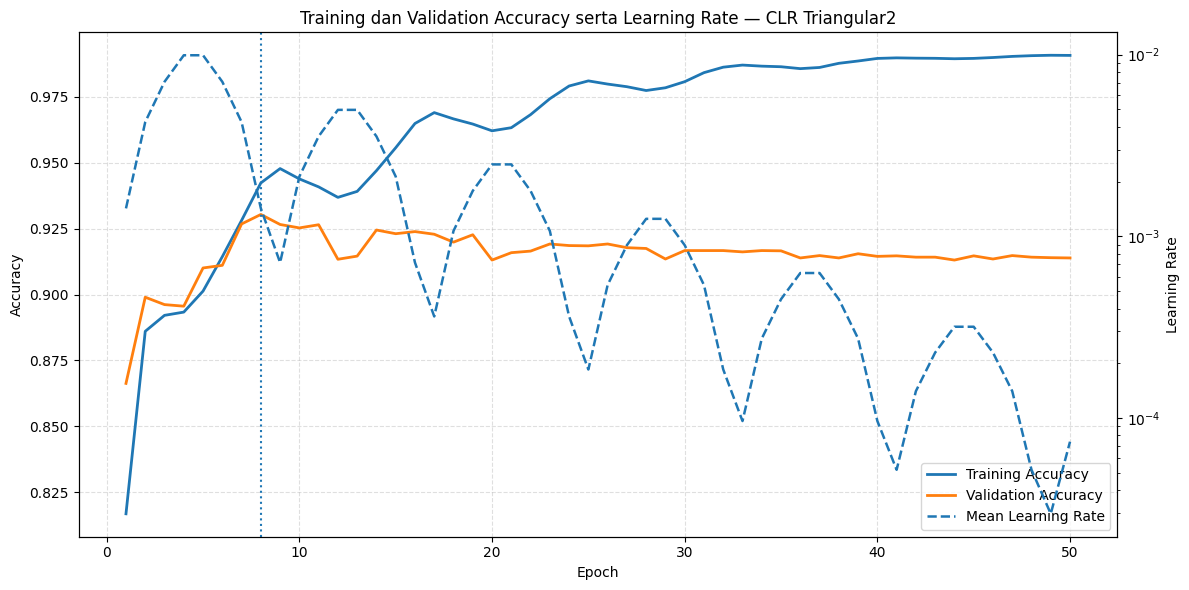

In [57]:
# Membuat area grafik accuracy dengan dua sumbu vertikal.
fig, ax1 = plt.subplots(
    figsize=(12, 6)
)

# Menggambar training accuracy pada sumbu pertama.
ax1.plot(
    epochs_axis_clr,
    clr_history_df["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

# Menggambar validation accuracy pada sumbu pertama.
ax1.plot(
    epochs_axis_clr,
    clr_history_df["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

# Memberikan label epoch pada sumbu horizontal.
ax1.set_xlabel("Epoch")

# Memberikan label accuracy pada sumbu vertikal pertama.
ax1.set_ylabel("Accuracy")

# Memberikan judul grafik.
ax1.set_title(
    "Training dan Validation Accuracy serta Learning Rate — CLR Triangular2"
)

# Menandai posisi epoch terbaik berdasarkan validation loss.
ax1.axvline(
    clr_best_epoch,
    linestyle=":",
    linewidth=1.5
)

# Membuat sumbu vertikal kedua untuk learning rate.
ax2 = ax1.twinx()

# Menggambar rata-rata learning rate setiap epoch.
ax2.plot(
    epochs_axis_clr,
    clr_history_df["Learning_Rate_Mean"],
    linestyle="--",
    linewidth=1.8,
    label="Mean Learning Rate"
)

# Memberikan label learning rate pada sumbu kedua.
ax2.set_ylabel("Learning Rate")

# Menggunakan skala logaritmik pada learning rate.
ax2.set_yscale("log")

# Mengambil legend dari sumbu accuracy.
lines_1, labels_1 = ax1.get_legend_handles_labels()

# Mengambil legend dari sumbu learning rate.
lines_2, labels_2 = ax2.get_legend_handles_labels()

# Menggabungkan legend dari kedua sumbu.
ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="best"
)

# Menampilkan grid pada grafik accuracy.
ax1.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Menyesuaikan tata letak grafik.
fig.tight_layout()

# Menampilkan grafik.
plt.show()

## Penentuan Epoch Terbaik CLR

Epoch terbaik ditentukan berdasarkan nilai validation loss terendah. Validation accuracy maksimum juga dicatat sebagai informasi tambahan.

In [58]:
# Menentukan epoch dengan validation loss terendah.
clr_best_epoch = (
    np.argmin(
        history_clr.history["val_loss"]
    ) + 1
)

# Mengambil validation loss pada epoch terbaik.
clr_best_val_loss = (
    history_clr.history["val_loss"][
        clr_best_epoch - 1
    ]
)

# Mengambil validation accuracy pada epoch terbaik.
clr_best_val_accuracy = (
    history_clr.history["val_accuracy"][
        clr_best_epoch - 1
    ]
)

# Menentukan epoch dengan validation accuracy tertinggi.
clr_best_acc_epoch = (
    np.argmax(
        history_clr.history["val_accuracy"]
    ) + 1
)

# Mengambil nilai validation accuracy tertinggi.
clr_best_acc_value = (
    history_clr.history["val_accuracy"][
        clr_best_acc_epoch - 1
    ]
)

# Menampilkan judul hasil epoch terbaik.
print("EPOCH TERBAIK - CLR TRIANGULAR2\n")

# Menampilkan epoch terbaik berdasarkan validation loss.
print(
    f"Best epoch berdasarkan val_loss: "
    f"{clr_best_epoch}"
)

# Menampilkan validation loss terbaik.
print(
    f"Best validation loss: "
    f"{clr_best_val_loss:.6f}"
)

# Menampilkan validation accuracy pada epoch tersebut.
print(
    f"Validation accuracy pada epoch : "
    f"{clr_best_val_accuracy:.6f}"
)

# Menampilkan epoch dengan validation accuracy maksimum.
print(
    f"Epoch validation accuracy max  : "
    f"{clr_best_acc_epoch}"
)

# Menampilkan validation accuracy maksimum.
print(
    f"Maximum validation accuracy    : "
    f"{clr_best_acc_value:.6f}"
)

EPOCH TERBAIK - CLR TRIANGULAR2

Best epoch berdasarkan val_loss: 8
Best validation loss: 0.186237
Validation accuracy pada epoch : 0.930400
Epoch validation accuracy max  : 8
Maximum validation accuracy    : 0.930400


## Evaluasi Model CLR pada Data Testing

Model terbaik yang telah dipilih berdasarkan validation loss dievaluasi menggunakan data testing yang tidak digunakan selama proses training.

In [59]:
# Membuat fungsi untuk memperoleh label, probabilitas, dan prediksi model.
def predict_dataset(model, dataset):

    # Mengambil seluruh label aktual dari dataset.
    y_true = np.concatenate([
        labels.numpy().astype(int).ravel()
        for _, labels in dataset
    ])

    # Menghasilkan probabilitas prediksi untuk seluruh data.
    y_prob = model.predict(
        dataset,
        verbose=0
    ).ravel()

    # Mengubah probabilitas menjadi kelas menggunakan threshold 0.5.
    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    # Mengembalikan label aktual, probabilitas, dan prediksi.
    return (
        y_true,
        y_prob,
        y_pred
    )


# Membuat fungsi untuk menghitung seluruh metrik evaluasi model.
def evaluate_model(
    model,
    dataset,
    split_name="Test"
):

    # Menghitung loss dan accuracy menggunakan Keras.
    evaluation = model.evaluate(
        dataset,
        verbose=0,
        return_dict=True
    )

    # Mengambil label aktual dan prediksi model.
    y_true, y_prob, y_pred = predict_dataset(
        model,
        dataset
    )

    # Menghitung precision dengan aman ketika tidak ada prediksi positif.
    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Menghitung recall dengan aman ketika tidak ada prediksi positif.
    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Menghitung F1-score dengan aman ketika tidak ada prediksi positif.
    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Menghitung confusion matrix berdasarkan label aktual dan prediksi.
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    # Membuat classification report dalam bentuk dictionary.
    report_dict = classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    # Mengembalikan seluruh hasil evaluasi dalam satu dictionary.
    return {
        "Split": split_name,
        "Loss": float(evaluation["loss"]),
        "Accuracy": float(evaluation["accuracy"]),
        "Precision": float(precision),
        "Recall": float(recall),
        "F1-score": float(f1),
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred,
        "confusion_matrix": cm,
        "classification_report": pd.DataFrame(
            report_dict
        ).T
    }

## Evaluasi CLR

In [60]:
# Mengevaluasi model CLR terbaik pada dataset testing.
clr_eval = evaluate_model(
    model_clr,
    test_ds,
    split_name="Test CLR"
)

# Menampilkan judul hasil testing.
print("HASIL TEST - CLR TRIANGULAR2")

# Menampilkan nilai loss model pada data testing.
print(
    f"Loss: {clr_eval['Loss']:.6f}"
)

# Menampilkan accuracy model pada data testing.
print(
    f"Accuracy: {clr_eval['Accuracy']:.6f}"
)

# Menampilkan precision model pada data testing.
print(
    f"Precision: {clr_eval['Precision']:.6f}"
)

# Menampilkan recall model pada data testing.
print(
    f"Recall: {clr_eval['Recall']:.6f}"
)

# Menampilkan F1-score model pada data testing.
print(
    f"F1-score: {clr_eval['F1-score']:.6f}"
)


HASIL TEST - CLR TRIANGULAR2
Loss: 0.192741
Accuracy: 0.926650
Precision: 0.933103
Recall: 0.919200
F1-score: 0.926099


## Classification Report dan Confusion Matrix CLR

CLASSIFICATION REPORT - CLR TRIANGULAR2



,precision,recall,f1-score,support
REAL,0.920386,0.93410,0.927192,10000.00000
FAKE,0.933103,0.91920,0.926099,10000.00000
accuracy,0.926650,0.92665,0.926650,0.92665
macro avg,0.926745,0.92665,0.926646,20000.00000
weighted avg,0.926745,0.92665,0.926646,20000.00000



CONFUSION MATRIX — CLR TRIANGULAR2

True Negative  (TN) : 9,341
False Positive (FP) : 659
False Negative (FN) : 808
True Positive  (TP) : 9,192


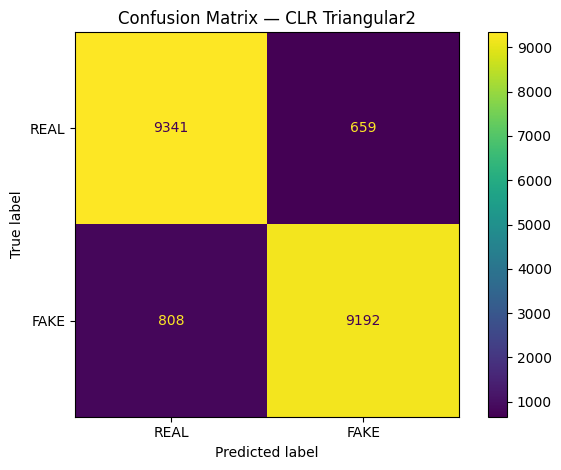

In [61]:
# Menampilkan classification report dalam bentuk tabel.
print("CLASSIFICATION REPORT - CLR TRIANGULAR2\n")

# Menampilkan precision, recall, F1-score, dan support setiap kelas.
display(
    clr_eval["classification_report"]
)

# Mengambil confusion matrix dari hasil evaluasi.
clr_cm = clr_eval["confusion_matrix"]

# Menguraikan confusion matrix menjadi TN, FP, FN, dan TP.
tn, fp, fn, tp = clr_cm.ravel()

# Memberikan jarak visual sebelum hasil confusion matrix.
print()

# Menampilkan judul confusion matrix.
print("CONFUSION MATRIX — CLR TRIANGULAR2")

# Memberikan jarak visual setelah judul.
print()

# Menampilkan jumlah True Negative.
print(f"True Negative  (TN) : {tn:,}")

# Menampilkan jumlah False Positive.
print(f"False Positive (FP) : {fp:,}")

# Menampilkan jumlah False Negative.
print(f"False Negative (FN) : {fn:,}")

# Menampilkan jumlah True Positive.
print(f"True Positive  (TP) : {tp:,}")

# Membuat objek visualisasi confusion matrix.
disp = ConfusionMatrixDisplay(
    confusion_matrix=clr_cm,
    display_labels=CLASS_NAMES
)

# Menggambar confusion matrix.
disp.plot(
    values_format="d"
)

# Memberikan judul pada confusion matrix.
plt.title(
    "Confusion Matrix — CLR Triangular2"
)

# Menyesuaikan tata letak grafik.
plt.tight_layout()

# Menampilkan confusion matrix.
plt.show()

## Penyimpanan Hasil Eksperimen CLR

In [62]:
# Membuat DataFrame berisi metrik akhir model CLR.
clr_test_results = pd.DataFrame([
    {
        "Strategy": "CLR Triangular2",
        "Loss": clr_eval["Loss"],
        "Accuracy": clr_eval["Accuracy"],
        "Precision": clr_eval["Precision"],
        "Recall": clr_eval["Recall"],
        "F1-score": clr_eval["F1-score"],
        "Best Epoch": clr_best_epoch,
        "Best Validation Loss": clr_best_val_loss,
        "Best Validation Accuracy": clr_best_val_accuracy
    }
])

# Menyimpan metrik testing model CLR ke file CSV.
clr_test_results.to_csv(
    RESULTS_DIR / "clr_test_results.csv",
    index=False
)

# Menyimpan history training CLR per epoch ke file CSV.
clr_history_df.to_csv(
    RESULTS_DIR / "clr_training_history.csv",
    index=False
)

# Menyimpan learning rate pada setiap training step ke file CSV.
clr_lr_history.to_csv(
    RESULTS_DIR / "clr_learning_rate_history.csv",
    index=False
)

# Menampilkan lokasi penyimpanan seluruh hasil eksperimen.
print(
    f"Semua hasil CLR berhasil disimpan di: "
    f"{RESULTS_DIR}"
)

Semua hasil CLR berhasil disimpan di: /content/results


# Perbandingan Fixed Learning Rate dan CLR Triangular2

Bagian ini membandingkan hasil eksperimen Fixed Learning Rate dan Cyclical Learning Rate (CLR) mode Triangular2.

Perbandingan dilakukan pada dua aspek, yaitu dinamika proses pelatihan berdasarkan validation loss dan validation accuracy, serta performa akhir model berdasarkan data testing.

Kedua skenario menggunakan arsitektur CNN, dataset, batch size, jumlah epoch, optimizer, dan fungsi loss yang sama. Perbedaan utama terletak pada strategi learning rate.

## Persiapan Data Perbandingan

Sebelum hasil dibandingkan, epoch terbaik dari masing-masing eksperimen ditentukan berdasarkan validation loss terendah. Model pada kedua skenario juga dievaluasi kembali menggunakan dataset testing dengan fungsi evaluasi yang sama.

In [63]:
# Memastikan history Fixed Learning Rate tersedia sebelum perbandingan.
if "history_fixed" not in globals():
    # Menghentikan proses jika history Fixed Learning Rate belum tersedia.
    raise NameError(
        "history_fixed belum tersedia. Jalankan training Fixed Learning Rate terlebih dahulu."
    )

# Memastikan history CLR tersedia sebelum perbandingan.
if "history_clr" not in globals():
    # Menghentikan proses jika history CLR belum tersedia.
    raise NameError(
        "history_clr belum tersedia. Jalankan training CLR terlebih dahulu."
    )

# Memastikan model Fixed Learning Rate tersedia sebelum evaluasi.
if "model_fixed" not in globals():
    # Menghentikan proses jika model Fixed Learning Rate belum tersedia.
    raise NameError(
        "model_fixed belum tersedia. Jalankan training Fixed Learning Rate terlebih dahulu."
    )

# Memastikan model CLR tersedia sebelum evaluasi.
if "model_clr" not in globals():
    # Menghentikan proses jika model CLR belum tersedia.
    raise NameError(
        "model_clr belum tersedia. Jalankan training CLR terlebih dahulu."
    )

# Menentukan epoch dengan validation loss terendah pada Fixed Learning Rate.
fixed_best_epoch = (
    np.argmin(
        history_fixed.history["val_loss"]
    ) + 1
)

# Menentukan epoch dengan validation loss terendah pada CLR Triangular2.
clr_best_epoch = (
    np.argmin(
        history_clr.history["val_loss"]
    ) + 1
)

# Mengambil validation loss terbaik Fixed Learning Rate.
fixed_best_val_loss = (
    history_fixed.history["val_loss"][
        fixed_best_epoch - 1
    ]
)

# Mengambil validation loss terbaik CLR Triangular2.
clr_best_val_loss = (
    history_clr.history["val_loss"][
        clr_best_epoch - 1
    ]
)

# Mengambil validation accuracy pada epoch terbaik Fixed Learning Rate.
fixed_best_val_accuracy = (
    history_fixed.history["val_accuracy"][
        fixed_best_epoch - 1
    ]
)

# Mengambil validation accuracy pada epoch terbaik CLR Triangular2.
clr_best_val_accuracy = (
    history_clr.history["val_accuracy"][
        clr_best_epoch - 1
    ]
)

# Mengevaluasi kembali model Fixed Learning Rate menggunakan dataset testing.
fixed_eval = evaluate_model(
    model_fixed,
    test_ds,
    split_name="Test Fixed LR"
)

# Mengevaluasi kembali model CLR menggunakan dataset testing.
clr_eval = evaluate_model(
    model_clr,
    test_ds,
    split_name="Test CLR"
)

# Menampilkan hasil epoch terbaik dari kedua eksperimen.
print("EPOCH TERBAIK\n")

# Menampilkan epoch terbaik Fixed Learning Rate.
print(
    f"Fixed LR best epoch : "
    f"{fixed_best_epoch}"
)

# Menampilkan epoch terbaik CLR.
print(
    f"CLR best epoch      : "
    f"{clr_best_epoch}"
)

# Menampilkan validation loss terbaik Fixed Learning Rate.
print(
    f"\nFixed LR best val_loss : "
    f"{fixed_best_val_loss:.6f}"
)

# Menampilkan validation loss terbaik CLR.
print(
    f"CLR best val_loss      : "
    f"{clr_best_val_loss:.6f}"
)

# Menampilkan validation accuracy pada epoch terbaik Fixed Learning Rate.
print(
    f"\nFixed LR val_accuracy : "
    f"{fixed_best_val_accuracy:.6f}"
)

# Menampilkan validation accuracy pada epoch terbaik CLR.
print(
    f"CLR val_accuracy      : "
    f"{clr_best_val_accuracy:.6f}"
)

EPOCH TERBAIK

Fixed LR best epoch : 9
CLR best epoch      : 8

Fixed LR best val_loss : 0.158009
CLR best val_loss      : 0.186237

Fixed LR val_accuracy : 0.940400
CLR val_accuracy      : 0.930400


## Perbandingan Metrik Testing

Performa akhir kedua model dibandingkan menggunakan data testing yang tidak digunakan selama proses pelatihan. Metrik yang dibandingkan meliputi loss, accuracy, precision, recall, dan F1-score.

Nilai delta dihitung sebagai selisih antara CLR Triangular2 dan Fixed Learning Rate.

In [65]:
# Membuat tabel perbandingan metrik testing kedua eksperimen.
comparison = pd.DataFrame({
    "Metric": [
        "Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],

    # Mengambil metrik testing dari hasil evaluasi Fixed Learning Rate.
    "Fixed LR": [
        fixed_eval["Loss"],
        fixed_eval["Accuracy"],
        fixed_eval["Precision"],
        fixed_eval["Recall"],
        fixed_eval["F1-score"]
    ],

    # Mengambil metrik testing dari hasil evaluasi CLR Triangular2.
    "CLR Triangular2": [
        clr_eval["Loss"],
        clr_eval["Accuracy"],
        clr_eval["Precision"],
        clr_eval["Recall"],
        clr_eval["F1-score"]
    ]
})

# Menghitung selisih nilai CLR terhadap Fixed Learning Rate.
comparison["Delta (CLR - Fixed)"] = (
    comparison["CLR Triangular2"]
    - comparison["Fixed LR"]
)

# Menampilkan judul tabel perbandingan.
print("=" * 60)
print("PERBANDINGAN HASIL TESTING")
print("=" * 60)

# Menampilkan tabel dengan format angka yang konsisten.
display(
    comparison.style.format({
        "Fixed LR": "{:.6f}",
        "CLR Triangular2": "{:.6f}",
        "Delta (CLR - Fixed)": "{:+.6f}"
    })
)

PERBANDINGAN HASIL TESTING


,Metric,Fixed LR,CLR Triangular2,Delta (CLR - Fixed)
0,Loss,0.164628,0.192741,+0.028113
1,Accuracy,0.938850,0.926650,-0.012200
2,Precision,0.938894,0.933103,-0.005791
3,Recall,0.938800,0.919200,-0.019600
4,F1-score,0.938847,0.926099,-0.012748


## Perbandingan Validation Loss

Validation loss digunakan untuk membandingkan dinamika pembelajaran kedua strategi learning rate selama proses pelatihan. Validation data tidak digunakan untuk memperbarui bobot model dan digunakan untuk memantau kemampuan generalisasi selama training.

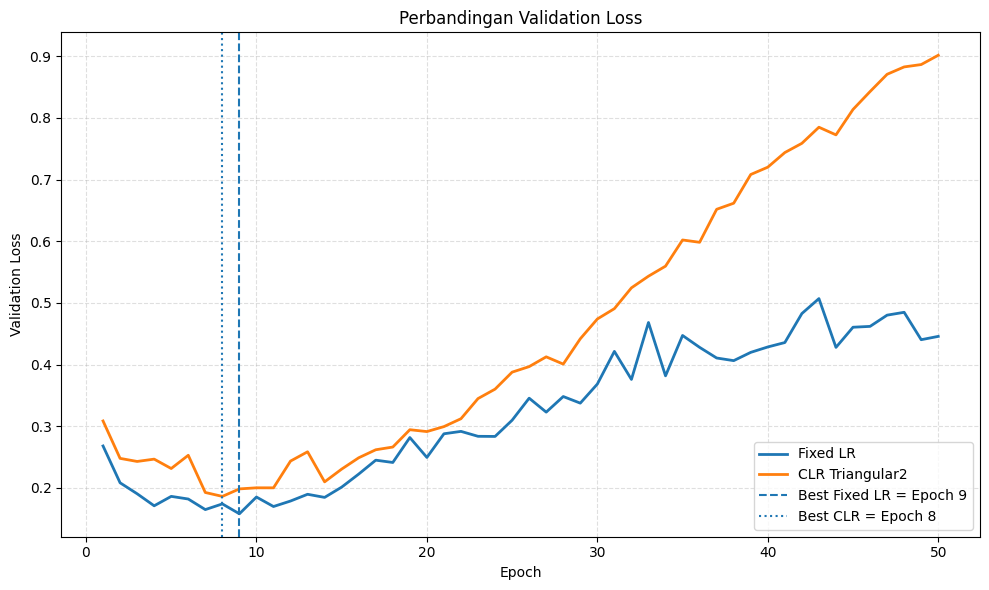

In [66]:
# Membuat sumbu epoch berdasarkan panjang history Fixed Learning Rate.
epochs_fixed = np.arange(
    1,
    len(history_fixed.history["val_loss"]) + 1
)

# Membuat sumbu epoch berdasarkan panjang history CLR.
epochs_clr = np.arange(
    1,
    len(history_clr.history["val_loss"]) + 1
)

# Membuat area grafik validation loss.
plt.figure(figsize=(10, 6))

# Menggambar validation loss Fixed Learning Rate.
plt.plot(
    epochs_fixed,
    history_fixed.history["val_loss"],
    label="Fixed LR",
    linewidth=2
)

# Menggambar validation loss CLR Triangular2.
plt.plot(
    epochs_clr,
    history_clr.history["val_loss"],
    label="CLR Triangular2",
    linewidth=2
)

# Menandai epoch terbaik Fixed Learning Rate.
plt.axvline(
    fixed_best_epoch,
    linestyle="--",
    linewidth=1.5,
    label=f"Best Fixed LR = Epoch {fixed_best_epoch}"
)

# Menandai epoch terbaik CLR.
plt.axvline(
    clr_best_epoch,
    linestyle=":",
    linewidth=1.5,
    label=f"Best CLR = Epoch {clr_best_epoch}"
)

# Memberikan label pada sumbu epoch.
plt.xlabel("Epoch")

# Memberikan label pada sumbu validation loss.
plt.ylabel("Validation Loss")

# Memberikan judul grafik.
plt.title(
    "Perbandingan Validation Loss"
)

# Menampilkan legend grafik.
plt.legend()

# Menampilkan grid agar perubahan kurva lebih mudah diamati.
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Menyesuaikan tata letak grafik.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

## Perbandingan Validation Accuracy

Validation accuracy dibandingkan untuk melihat perkembangan kemampuan klasifikasi kedua model selama proses pelatihan.

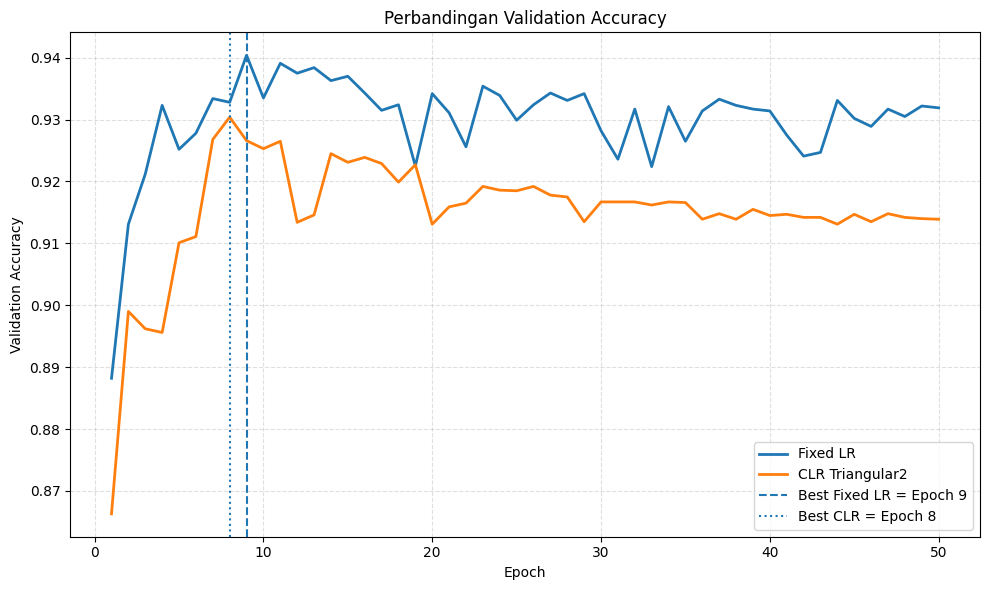

In [67]:
# Membuat area grafik validation accuracy.
plt.figure(figsize=(10, 6))

# Menggambar validation accuracy Fixed Learning Rate.
plt.plot(
    epochs_fixed,
    history_fixed.history["val_accuracy"],
    label="Fixed LR",
    linewidth=2
)

# Menggambar validation accuracy CLR Triangular2.
plt.plot(
    epochs_clr,
    history_clr.history["val_accuracy"],
    label="CLR Triangular2",
    linewidth=2
)

# Menandai epoch terbaik Fixed Learning Rate.
plt.axvline(
    fixed_best_epoch,
    linestyle="--",
    linewidth=1.5,
    label=f"Best Fixed LR = Epoch {fixed_best_epoch}"
)

# Menandai epoch terbaik CLR.
plt.axvline(
    clr_best_epoch,
    linestyle=":",
    linewidth=1.5,
    label=f"Best CLR = Epoch {clr_best_epoch}"
)

# Memberikan label pada sumbu epoch.
plt.xlabel("Epoch")

# Memberikan label pada sumbu validation accuracy.
plt.ylabel("Validation Accuracy")

# Memberikan judul grafik.
plt.title(
    "Perbandingan Validation Accuracy"
)

# Menampilkan legend grafik.
plt.legend()

# Menampilkan grid agar kurva mudah dibaca.
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Menyesuaikan tata letak grafik.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

## Visualisasi Perbandingan Metrik Testing

Visualisasi digunakan untuk memperlihatkan perbedaan performa akhir Fixed Learning Rate dan CLR Triangular2 pada data testing.

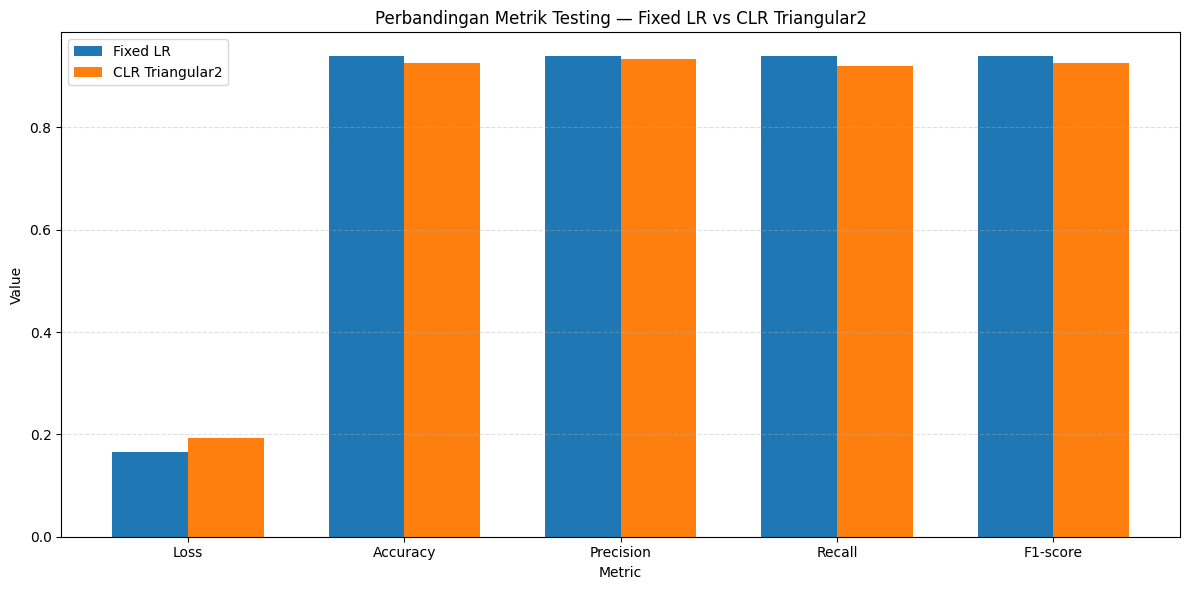

In [68]:
# Menentukan posisi setiap metrik pada sumbu horizontal.
metric_positions = np.arange(
    len(comparison["Metric"])
)

# Menentukan lebar setiap batang.
bar_width = 0.35

# Membuat area grafik perbandingan metrik.
plt.figure(figsize=(12, 6))

# Menggambar metrik Fixed Learning Rate.
plt.bar(
    metric_positions - bar_width / 2,
    comparison["Fixed LR"],
    width=bar_width,
    label="Fixed LR"
)

# Menggambar metrik CLR Triangular2.
plt.bar(
    metric_positions + bar_width / 2,
    comparison["CLR Triangular2"],
    width=bar_width,
    label="CLR Triangular2"
)

# Mengatur posisi label metrik pada sumbu horizontal.
plt.xticks(
    metric_positions,
    comparison["Metric"]
)

# Memberikan label pada sumbu horizontal.
plt.xlabel("Metric")

# Memberikan label pada sumbu vertikal.
plt.ylabel("Value")

# Memberikan judul grafik.
plt.title(
    "Perbandingan Metrik Testing — Fixed LR vs CLR Triangular2"
)

# Menampilkan legend.
plt.legend()

# Menampilkan grid horizontal untuk membantu membaca nilai.
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

# Menyesuaikan tata letak grafik.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

# Ringkasan Eksperimen

Ringkasan eksperimen menyatukan konfigurasi utama penelitian, parameter learning rate, epoch terbaik, serta hasil testing dari Fixed Learning Rate dan CLR Triangular2.

In [69]:
# Membuat tabel ringkasan parameter dan hasil eksperimen.
experiment_summary = pd.DataFrame({
    "Parameter": [
        "Training images",
        "Validation images",
        "Testing images",
        "Image size",
        "Batch size",
        "Epoch maksimum",
        "Seed",
        "Optimizer",
        "Loss function",
        "Fixed learning rate",
        "LRRT start",
        "LRRT end",
        "LRRT epochs",
        "CLR base_lr",
        "CLR max_lr",
        "CLR step_size",
        "CLR full cycle",
        "Fixed best epoch",
        "CLR best epoch",
        "Fixed best validation loss",
        "CLR best validation loss",
        "Fixed best validation accuracy",
        "CLR best validation accuracy",
        "Fixed test loss",
        "CLR test loss",
        "Fixed test accuracy",
        "CLR test accuracy",
        "Fixed test precision",
        "CLR test precision",
        "Fixed test recall",
        "CLR test recall",
        "Fixed test F1-score",
        "CLR test F1-score"
    ],

    "Value": [
        # Mengambil jumlah data training.
        len(train_paths),

        # Mengambil jumlah data validation.
        len(val_paths),

        # Mengambil jumlah data testing.
        len(test_paths),

        # Mengambil ukuran tinggi citra.
        f"{IMG_HEIGHT} × {IMG_WIDTH} × {IMG_CHANNELS}",

        # Mengambil batch size penelitian.
        BATCH_SIZE,

        # Mengambil jumlah epoch training utama.
        EPOCHS,

        # Mengambil random seed penelitian.
        SEED,

        # Menuliskan optimizer yang digunakan.
        "Adam",

        # Menuliskan fungsi loss yang digunakan.
        "Binary Cross Entropy",

        # Mengambil fixed learning rate.
        FIXED_LR,

        # Mengambil learning rate awal LRRT.
        LRRT_START,

        # Mengambil learning rate akhir LRRT.
        LRRT_END,

        # Mengambil jumlah epoch LRRT.
        LRRT_EPOCHS,

        # Mengambil BASE_LR hasil LRRT.
        BASE_LR,

        # Mengambil MAX_LR hasil LRRT.
        MAX_LR,

        # Mengambil step size CLR.
        STEP_SIZE,

        # Menghitung satu siklus penuh CLR.
        2 * STEP_SIZE,

        # Mengambil epoch terbaik Fixed Learning Rate.
        fixed_best_epoch,

        # Mengambil epoch terbaik CLR.
        clr_best_epoch,

        # Mengambil validation loss terbaik Fixed Learning Rate.
        fixed_best_val_loss,

        # Mengambil validation loss terbaik CLR.
        clr_best_val_loss,

        # Mengambil validation accuracy pada epoch terbaik Fixed Learning Rate.
        fixed_best_val_accuracy,

        # Mengambil validation accuracy pada epoch terbaik CLR.
        clr_best_val_accuracy,

        # Mengambil test loss Fixed Learning Rate.
        fixed_eval["Loss"],

        # Mengambil test loss CLR.
        clr_eval["Loss"],

        # Mengambil test accuracy Fixed Learning Rate.
        fixed_eval["Accuracy"],

        # Mengambil test accuracy CLR.
        clr_eval["Accuracy"],

        # Mengambil test precision Fixed Learning Rate.
        fixed_eval["Precision"],

        # Mengambil test precision CLR.
        clr_eval["Precision"],

        # Mengambil test recall Fixed Learning Rate.
        fixed_eval["Recall"],

        # Mengambil test recall CLR.
        clr_eval["Recall"],

        # Mengambil test F1-score Fixed Learning Rate.
        fixed_eval["F1-score"],

        # Mengambil test F1-score CLR.
        clr_eval["F1-score"]
    ]
})

# Menampilkan tabel ringkasan eksperimen.
display(
    experiment_summary
)

,Parameter,Value
0,Training images,90000
1,Validation images,10000
2,Testing images,20000
3,Image size,32 × 32 × 3
4,Batch size,32
5,Epoch maksimum,50
6,Seed,1
7,Optimizer,Adam
8,Loss function,Binary Cross Entropy
9,Fixed learning rate,0.001
